In [ ]:
import numpy as np
import shutil

actions= ['test','train']

for action in actions:
    for i in range(1,11):
                
        # -----------------------------
        # Input files
        # -----------------------------
        npy_in = f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/{action}/DAYMET_19800101_20141231_forcing_baseflow.npy"
        json_in = f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/{action}/DAYMET_19800101_20141231_forcing_baseflow_name.json"
        attr_in = f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/{action}/daymet_19800101_20141231_attr_671.npy"

        # -----------------------------
        # Output files
        # -----------------------------
        npy_out = f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/{action}/DAYMET_19800101_20141231_forcing_baseflow_mmday.npy"
        json_out = f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/{action}/DAYMET_19800101_20141231_forcing_baseflow_mmday_name.json"

        # -----------------------------
        # Load data
        # -----------------------------
        frc = np.load(npy_in)
        attr = np.load(attr_in)

        print("Forcing shape:", frc.shape)
        print("Attribute shape:", attr.shape)

        # -----------------------------
        # Basin area (index 11)
        # Units: km²
        # -----------------------------
        area_km2 = attr[:, 11]
        area_m2 = area_km2 * 1e6

        # -----------------------------
        # Convert baseflow:
        # ft³/s -> m³/day -> m/day
        # -----------------------------
        FT3S_TO_M3DAY = 0.0283168 * 86400  # 2446.57152

        # Convert ft³/s to m³/day
        frc[:, :, -1] *= FT3S_TO_M3DAY

        # Convert m³/day to m/day by dividing by basin area
        frc[:, :, -1] /= area_m2[:, np.newaxis]

        # m/day -> mm/day
        frc[:, :, -1] *= 1000.0

        # -----------------------------
        # Save converted data
        # -----------------------------
        np.save(npy_out, frc)

        # Copy variable-name JSON
        shutil.copy(json_in, json_out)

        # -----------------------------
        # Summary
        # -----------------------------
        print("\nConversion completed successfully.")
        print(f"Conversion factor (ft³/s -> m³/day): {FT3S_TO_M3DAY:.5f}")
        print(f"Output NumPy file: {npy_out}")
        print(f"Output JSON file: {json_out}")

        # -----------------------------
        # Verification
        # -----------------------------
        print("\nFirst basin area (km²):", area_km2[0])
        print("First five converted baseflow values (m/day):")
        print(frc[0, :5, -1])

        print("\nRange of converted baseflow (m/day):")
        print("Min:", np.nanmin(frc[:, :, -1]))
        print("Max:", np.nanmax(frc[:, :, -1]))
        print("Mean:", np.nanmean(frc[:, :, -1]))

Forcing shape: (52, 12784, 16)
Attribute shape: (52, 35)

Conversion completed successfully.
Conversion factor (ft³/s -> m³/day): 2446.57152
Output NumPy file: /home/s0shar47/scratch/BASEFLOW_FOLDS/1/test/DAYMET_19800101_20141231_forcing_baseflow_mmday.npy
Output JSON file: /home/s0shar47/scratch/BASEFLOW_FOLDS/1/test/DAYMET_19800101_20141231_forcing_baseflow_mmday_name.json

First basin area (km²): 228.55
First five converted baseflow values (m/day):
[0.63434777 0.62856635 0.62185224 0.6142462  0.60637978]

Range of converted baseflow (m/day):
Min: 0.0
Max: 21.291452325011644
Mean: 0.7201427184889472
Forcing shape: (54, 12784, 16)
Attribute shape: (54, 35)

Conversion completed successfully.
Conversion factor (ft³/s -> m³/day): 2446.57152
Output NumPy file: /home/s0shar47/scratch/BASEFLOW_FOLDS/2/test/DAYMET_19800101_20141231_forcing_baseflow_mmday.npy
Output JSON file: /home/s0shar47/scratch/BASEFLOW_FOLDS/2/test/DAYMET_19800101_20141231_forcing_baseflow_mmday_name.json

First basin 

: 

In [69]:
import numpy as np


all_ob_flow_values = []
all_ob_baseflow_values = []
all_sim_flow_old_values= []
all_sim_flow_new_values= []
all_sim_gwflow_old_values= []
all_sim_gwflow_new_values= []

for i in range(1, 11):
    # Load data
    ob_flow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/00060_Mean.npy"
    )

    ob_baseflow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/baseflow.npy"
    )

    sim_flow_old = np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
    )

    sim_flow_new = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
    )

    sim_gwflow_old = np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/gwflow.npy"
    )

    sim_gwflow_new = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/gwflow.npy"
    )
    sim_flow_old= np.squeeze(sim_flow_old)
    sim_flow_new= np.squeeze(sim_flow_new)
    sim_gwflow_old= np.squeeze(sim_gwflow_old)
    sim_gwflow_new= np.squeeze(sim_gwflow_new)

    # Flatten and store
    all_ob_flow_values.append(ob_flow.ravel())
    all_ob_baseflow_values.append(ob_baseflow.ravel())
    all_sim_flow_old_values.append(sim_flow_old.ravel())
    all_sim_flow_new_values.append(sim_flow_new.ravel())
    all_sim_gwflow_old_values.append(sim_gwflow_old.ravel())
    all_sim_gwflow_new_values.append(sim_gwflow_new.ravel())


# # Concatenate all folds

flat_ob_flow = np.concatenate(all_ob_flow_values)
flat_ob_baseflow = np.concatenate(all_ob_baseflow_values)
flat_sim_flow_old = np.concatenate(all_sim_flow_old_values)
flat_sim_flow_new = np.concatenate(all_sim_flow_new_values)
flat_sim_gwflow_old = np.concatenate(all_sim_gwflow_old_values)
flat_sim_gwflow_new = np.concatenate(all_sim_gwflow_new_values)

global_ob_mean_flow = np.mean(flat_ob_flow)
global_ob_mean_baseflow = np.mean(flat_ob_baseflow)



###Case1

num_flow1= np.sum((flat_ob_flow - flat_sim_flow_old) ** 2)
den_flow1= np.sum((flat_ob_flow - global_ob_mean_flow) ** 2)
nsef1=  1 - num_flow1 / den_flow1

num_baseflow1= np.sum((flat_ob_baseflow - flat_sim_gwflow_old) ** 2)
den_baseflow1= np.sum((flat_ob_baseflow - global_ob_mean_baseflow) ** 2)
nseb1=  1 - num_baseflow1 / den_baseflow1


###Case2

num_flow2= np.sum((flat_ob_flow - flat_sim_flow_new) ** 2)
den_flow2= np.sum((flat_ob_flow - global_ob_mean_flow) ** 2)
nsef2=  1 - num_flow2 / den_flow2

num_baseflow2= np.sum((flat_ob_baseflow - flat_sim_gwflow_new) ** 2)
den_baseflow2= np.sum((flat_ob_baseflow - global_ob_mean_baseflow) ** 2)
nseb2=  1 - num_baseflow2 / den_baseflow2

print(f"The Global NSE for total flow changed from {nsef1} to {nsef2}")
print(f"The Global NSE for baseflow changed from {nseb1} to {nseb2}")

The Global NSE for total flow changed from 0.7752697467803955 to 0.7655037641525269
The Global NSE for baseflow changed from 0.7052691578865051 to 0.7774702310562134


In [88]:
import numpy as np
nses= []
for i in range(1, 11):
    # Load data
    ob_flow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/00060_Mean.npy"
    )

    ob_baseflow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/baseflow.npy"
    )

    sim_flow_old = np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
    )

    sim_flow_new = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
    )

    sim_gwflow_old = np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/gwflow.npy"
    )

    sim_gwflow_new = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/gwflow.npy"
    )
    sim_flow_old= np.squeeze(sim_flow_old)
    sim_flow_new= np.squeeze(sim_flow_new)
    sim_gwflow_old= np.squeeze(sim_gwflow_old)
    sim_gwflow_new= np.squeeze(sim_gwflow_new)

    for k in range(ob_flow.shape[-1]):
        num= np.sum((ob_baseflow[:,k] - sim_gwflow_old[:,k]) ** 2)
        den= np.sum((ob_baseflow[:,k] - ob_baseflow[:,k].mean()) ** 2)
        nse= 1-num/den
        nses.append(nse)
med = np.median(nses)

med

np.float32(0.47505945)

In [107]:
import numpy as np

# ============================================================
# Metric functions
# ============================================================

def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den


def calc_kge(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    r = np.corrcoef(obs, sim)[0, 1]

    std_obs = np.std(obs)
    std_sim = np.std(sim)

    if std_obs == 0:
        return np.nan

    alpha = std_sim / std_obs

    mean_obs = np.mean(obs)
    if mean_obs == 0:
        return np.nan

    beta = np.mean(sim) / mean_obs

    return 1 - np.sqrt(
        (r - 1) ** 2 +
        (alpha - 1) ** 2 +
        (beta - 1) ** 2
    )


def calc_bias(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)
    if den == 0:
        return np.nan

    return (np.sum(sim) - den) / den


def calc_abs_bias(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)
    if den == 0:
        return np.nan

    return np.abs(np.sum(sim) - den) / den


# ============================================================
# Containers
# ============================================================

metrics_old = {
    "NSE": [],
    "KGE": [],
    "Bias": [],
    "AbsBias": [],
    "NSE_low": [],
    "NSE_high": [],
    "Bias_low": [],
    "Bias_high": [],
    "AbsBias_low": [],
    "AbsBias_high": [],
}

metrics_new = {
    "NSE": [],
    "KGE": [],
    "Bias": [],
    "AbsBias": [],
    "NSE_low": [],
    "NSE_high": [],
    "Bias_low": [],
    "Bias_high": [],
    "AbsBias_low": [],
    "AbsBias_high": [],
}

# ============================================================
# Loop over folds
# ============================================================

for i in range(1, 11):

    ob_baseflow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/baseflow.npy"
    )

    sim_gwflow_old = np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/gwflow.npy"
    )

    sim_gwflow_new = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/gwflow.npy"
    )

    sim_gwflow_old = np.squeeze(sim_gwflow_old)
    sim_gwflow_new = np.squeeze(sim_gwflow_new)

    # --------------------------------------------------------
    # Loop over basins
    # --------------------------------------------------------
    for k in range(ob_baseflow.shape[1]):

        obs = ob_baseflow[:, k]
        old = sim_gwflow_old[:, k]
        new = sim_gwflow_new[:, k]

        # =====================================================
        # Overall metrics
        # =====================================================
        metrics_old["NSE"].append(calc_nse(obs, old))
        metrics_new["NSE"].append(calc_nse(obs, new))

        metrics_old["KGE"].append(calc_kge(obs, old))
        metrics_new["KGE"].append(calc_kge(obs, new))

        metrics_old["Bias"].append(calc_bias(obs, old))
        metrics_new["Bias"].append(calc_bias(obs, new))

        metrics_old["AbsBias"].append(calc_abs_bias(obs, old))
        metrics_new["AbsBias"].append(calc_abs_bias(obs, new))

        # =====================================================
        # Low / High flow
        # =====================================================
        threshold = np.median(obs)

        low = obs <= threshold
        high = obs > threshold

        # ---------------- Low flow ----------------
        if np.sum(low) > 2:

            metrics_old["NSE_low"].append(calc_nse(obs[low], old[low]))
            metrics_new["NSE_low"].append(calc_nse(obs[low], new[low]))

            metrics_old["Bias_low"].append(calc_bias(obs[low], old[low]))
            metrics_new["Bias_low"].append(calc_bias(obs[low], new[low]))

            metrics_old["AbsBias_low"].append(
                calc_abs_bias(obs[low], old[low])
            )
            metrics_new["AbsBias_low"].append(
                calc_abs_bias(obs[low], new[low])
            )

        # ---------------- High flow ----------------
        if np.sum(high) > 2:

            metrics_old["NSE_high"].append(calc_nse(obs[high], old[high]))
            metrics_new["NSE_high"].append(calc_nse(obs[high], new[high]))

            metrics_old["Bias_high"].append(calc_bias(obs[high], old[high]))
            metrics_new["Bias_high"].append(calc_bias(obs[high], new[high]))

            metrics_old["AbsBias_high"].append(
                calc_abs_bias(obs[high], old[high])
            )
            metrics_new["AbsBias_high"].append(
                calc_abs_bias(obs[high], new[high])
            )

# ============================================================
# Print comparison
# ============================================================

print("\n" + "=" * 60)
print("GROUNDWATER / BASEFLOW COMPARISON")
print("=" * 60)

metric_order = [
    "NSE",
    "KGE",
    "Bias",
    "AbsBias",
    "NSE_low",
    "NSE_high",
    "Bias_low",
    "Bias_high",
    "AbsBias_low",
    "AbsBias_high",
]

for metric in metric_order:
    old = np.nanmedian(metrics_old[metric])
    new = np.nanmedian(metrics_new[metric])
    print(f"{metric:<13}: {old:8.4f} → {new:8.4f}")

print("=" * 60)


GROUNDWATER / BASEFLOW COMPARISON
NSE          :   0.4751 →   0.6952
KGE          :   0.5086 →   0.6732
Bias         :   0.1777 →   0.0088
AbsBias      :   0.2886 →   0.1924
NSE_low      :  -5.4412 →  -1.5150
NSE_high     :   0.1836 →   0.5022
Bias_low     :   0.7053 →   0.2644
Bias_high    :   0.1053 →  -0.0294
AbsBias_low  :   0.7133 →   0.4212
AbsBias_high :   0.2637 →   0.1738


In [106]:
import numpy as np

# ============================================================
# Metric functions
# ============================================================

def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den


def calc_kge(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    r = np.corrcoef(obs, sim)[0, 1]

    std_obs = np.std(obs)
    std_sim = np.std(sim)

    if std_obs == 0:
        return np.nan

    alpha = std_sim / std_obs

    mean_obs = np.mean(obs)
    if mean_obs == 0:
        return np.nan

    beta = np.mean(sim) / mean_obs

    return 1 - np.sqrt(
        (r - 1) ** 2 +
        (alpha - 1) ** 2 +
        (beta - 1) ** 2
    )


def calc_bias(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)
    if den == 0:
        return np.nan

    return (np.sum(sim) - den) / den


def calc_abs_bias(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)
    if den == 0:
        return np.nan

    return np.abs(np.sum(sim) - den) / den


# ============================================================
# Containers
# ============================================================

metrics_old = {
    "NSE": [],
    "KGE": [],
    "Bias": [],
    "AbsBias": [],
    "NSE_low": [],
    "NSE_high": [],
    "Bias_low": [],
    "Bias_high": [],
    "AbsBias_low": [],
    "AbsBias_high": [],
}

metrics_new = {
    "NSE": [],
    "KGE": [],
    "Bias": [],
    "AbsBias": [],
    "NSE_low": [],
    "NSE_high": [],
    "Bias_low": [],
    "Bias_high": [],
    "AbsBias_low": [],
    "AbsBias_high": [],
}

# ============================================================
# Loop over folds
# ============================================================

for i in range(1, 11):

    obs_flow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/00060_Mean.npy"
    )

    sim_old = np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
    )

    sim_new = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
    )

    sim_old = np.squeeze(sim_old)
    sim_new = np.squeeze(sim_new)

    # --------------------------------------------------------
    # Loop over basins
    # --------------------------------------------------------
    for k in range(obs_flow.shape[1]):

        obs = obs_flow[:, k]
        old = sim_old[:, k]
        new = sim_new[:, k]

        # =====================================================
        # Overall metrics
        # =====================================================
        metrics_old["NSE"].append(calc_nse(obs, old))
        metrics_new["NSE"].append(calc_nse(obs, new))

        metrics_old["KGE"].append(calc_kge(obs, old))
        metrics_new["KGE"].append(calc_kge(obs, new))

        metrics_old["Bias"].append(calc_bias(obs, old))
        metrics_new["Bias"].append(calc_bias(obs, new))

        metrics_old["AbsBias"].append(calc_abs_bias(obs, old))
        metrics_new["AbsBias"].append(calc_abs_bias(obs, new))

        # =====================================================
        # Low / High flow
        # =====================================================
        threshold = np.median(obs)

        low = obs <= threshold
        high = obs > threshold

        # ---------------- Low flow ----------------
        if np.sum(low) > 2:

            metrics_old["NSE_low"].append(calc_nse(obs[low], old[low]))
            metrics_new["NSE_low"].append(calc_nse(obs[low], new[low]))

            metrics_old["Bias_low"].append(calc_bias(obs[low], old[low]))
            metrics_new["Bias_low"].append(calc_bias(obs[low], new[low]))

            metrics_old["AbsBias_low"].append(
                calc_abs_bias(obs[low], old[low])
            )
            metrics_new["AbsBias_low"].append(
                calc_abs_bias(obs[low], new[low])
            )

        # ---------------- High flow ----------------
        if np.sum(high) > 2:

            metrics_old["NSE_high"].append(calc_nse(obs[high], old[high]))
            metrics_new["NSE_high"].append(calc_nse(obs[high], new[high]))

            metrics_old["Bias_high"].append(calc_bias(obs[high], old[high]))
            metrics_new["Bias_high"].append(calc_bias(obs[high], new[high]))

            metrics_old["AbsBias_high"].append(
                calc_abs_bias(obs[high], old[high])
            )
            metrics_new["AbsBias_high"].append(
                calc_abs_bias(obs[high], new[high])
            )

# ============================================================
# Print comparison
# ============================================================

print("\n" + "=" * 60)
print("TOTAL FLOW COMPARISON")
print("=" * 60)

metric_order = [
    "NSE",
    "KGE",
    "Bias",
    "AbsBias",
    "NSE_low",
    "NSE_high",
    "Bias_low",
    "Bias_high",
    "AbsBias_low",
    "AbsBias_high",
]

for metric in metric_order:
    old = np.nanmedian(metrics_old[metric])
    new = np.nanmedian(metrics_new[metric])
    print(f"{metric:<13}: {old:8.4f} → {new:8.4f}")

print("=" * 60)


TOTAL FLOW COMPARISON
NSE          :   0.6987 →   0.6921
KGE          :   0.7000 →   0.6929
Bias         :  -0.0162 →  -0.0274
AbsBias      :   0.1133 →   0.1110
NSE_low      :  -3.1764 →  -2.2929
NSE_high     :   0.6405 →   0.6330
Bias_low     :   0.3100 →   0.1991
Bias_high    :  -0.0498 →  -0.0550
AbsBias_low  :   0.4036 →   0.3479
AbsBias_high :   0.1191 →   0.1238


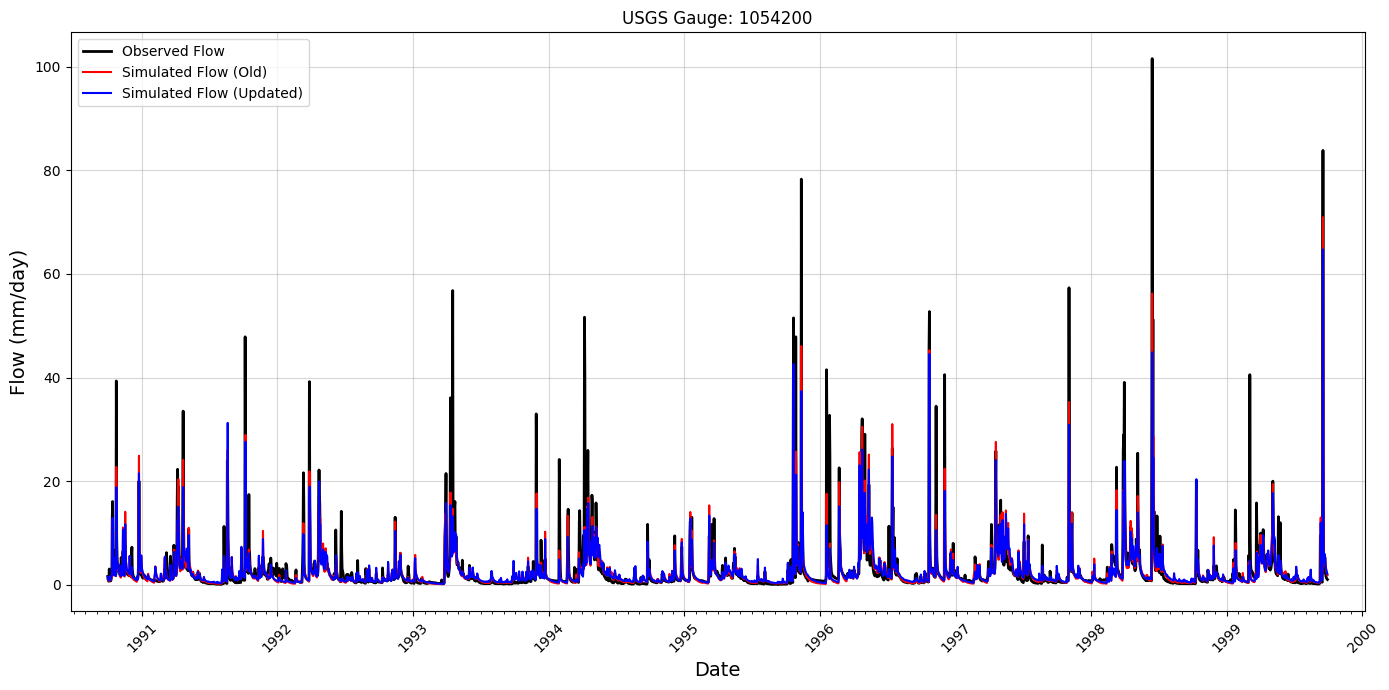

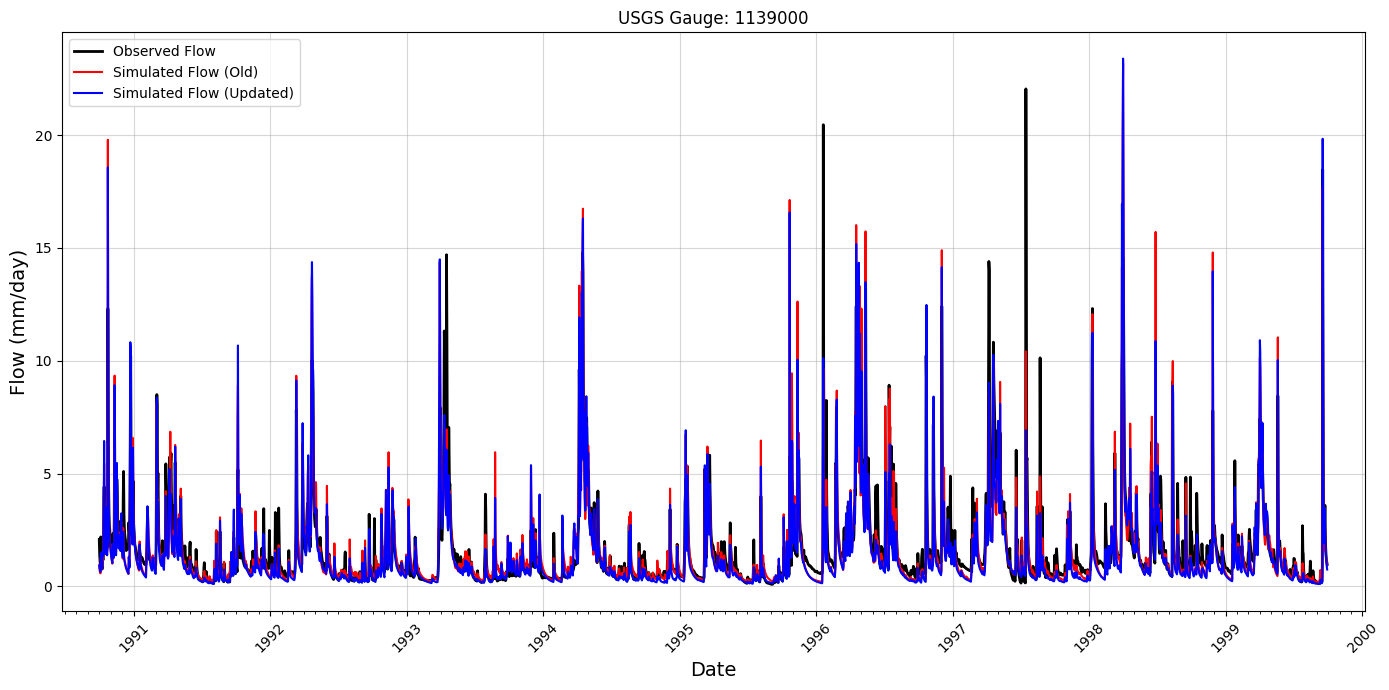

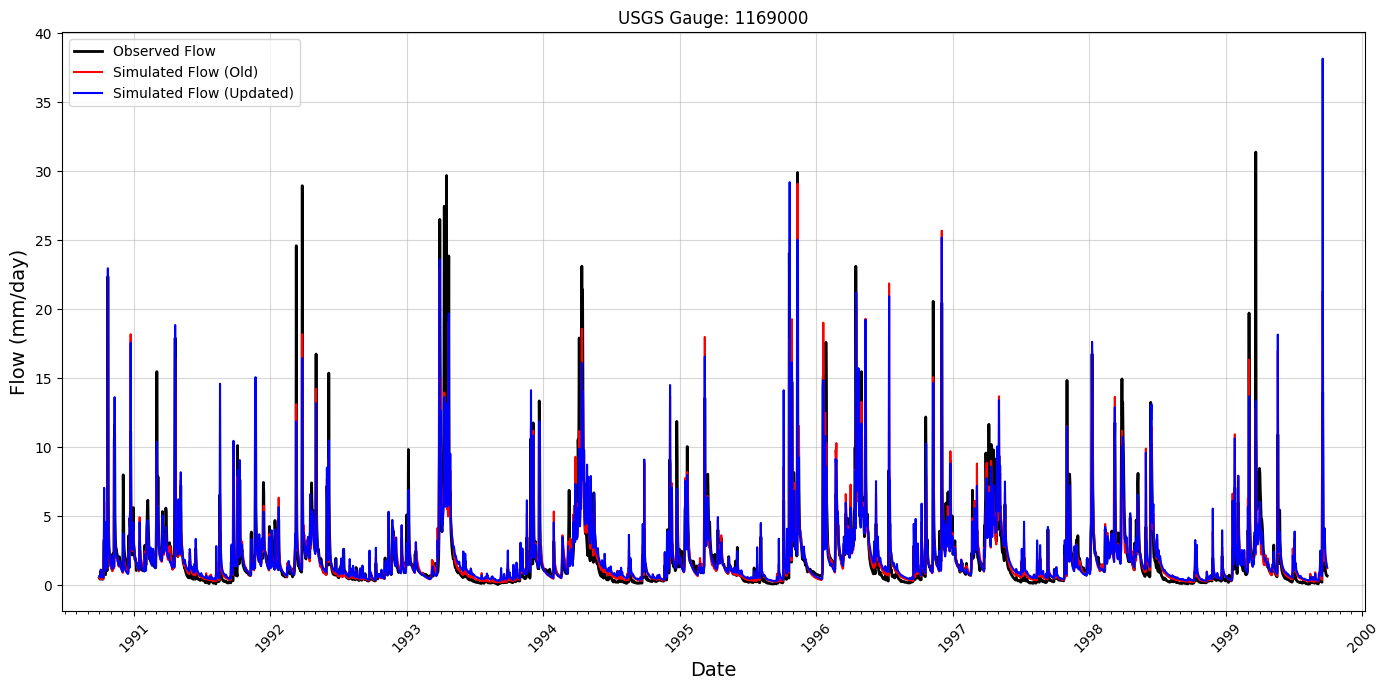

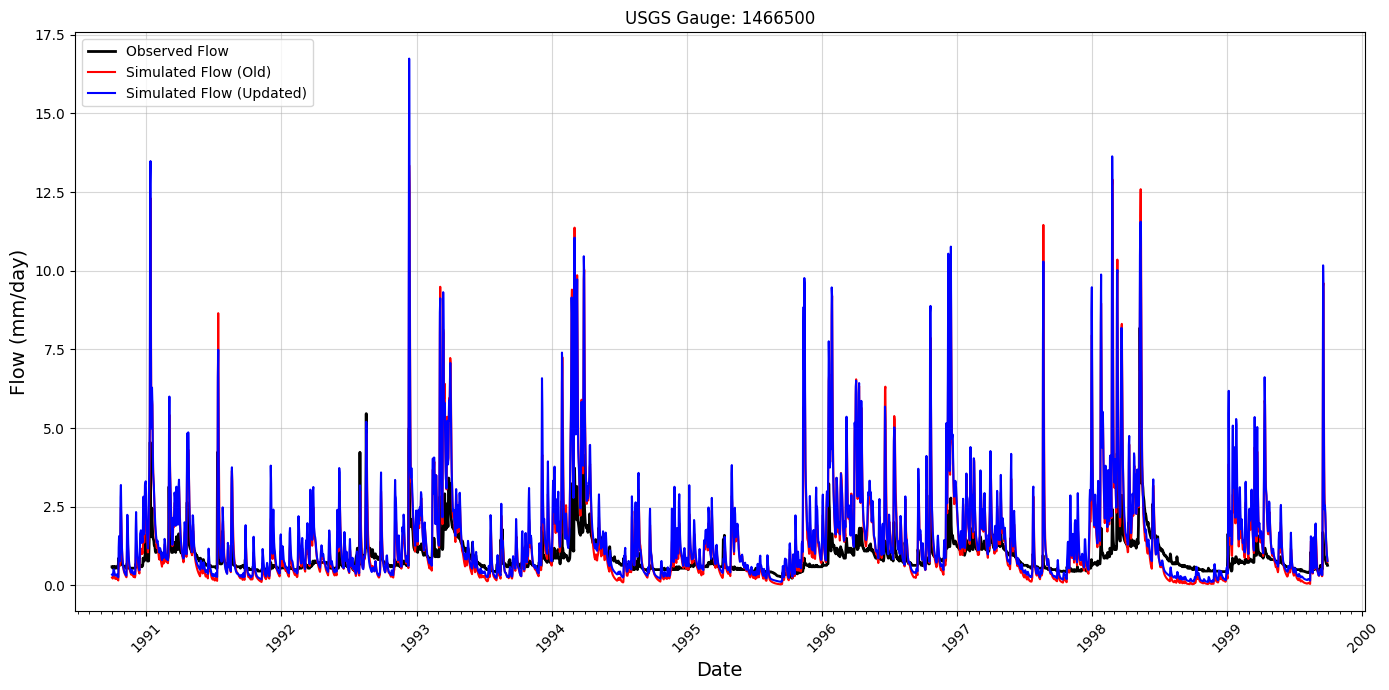

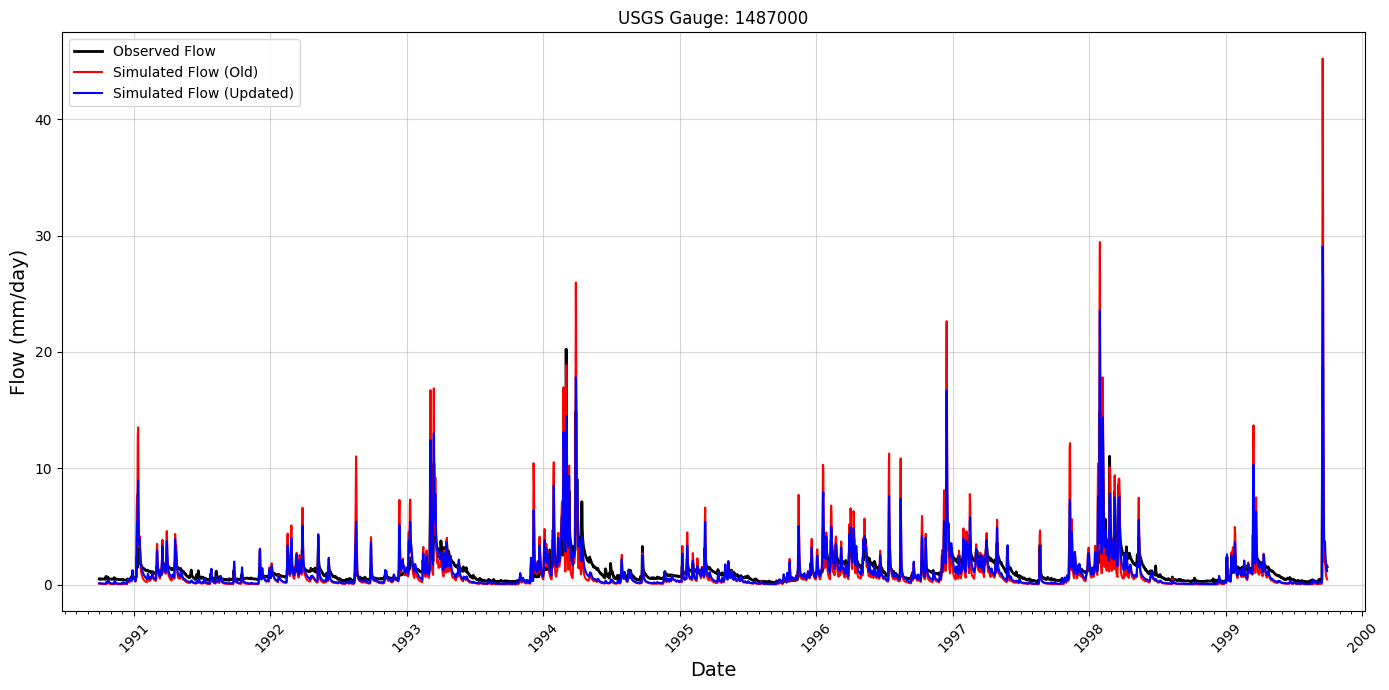

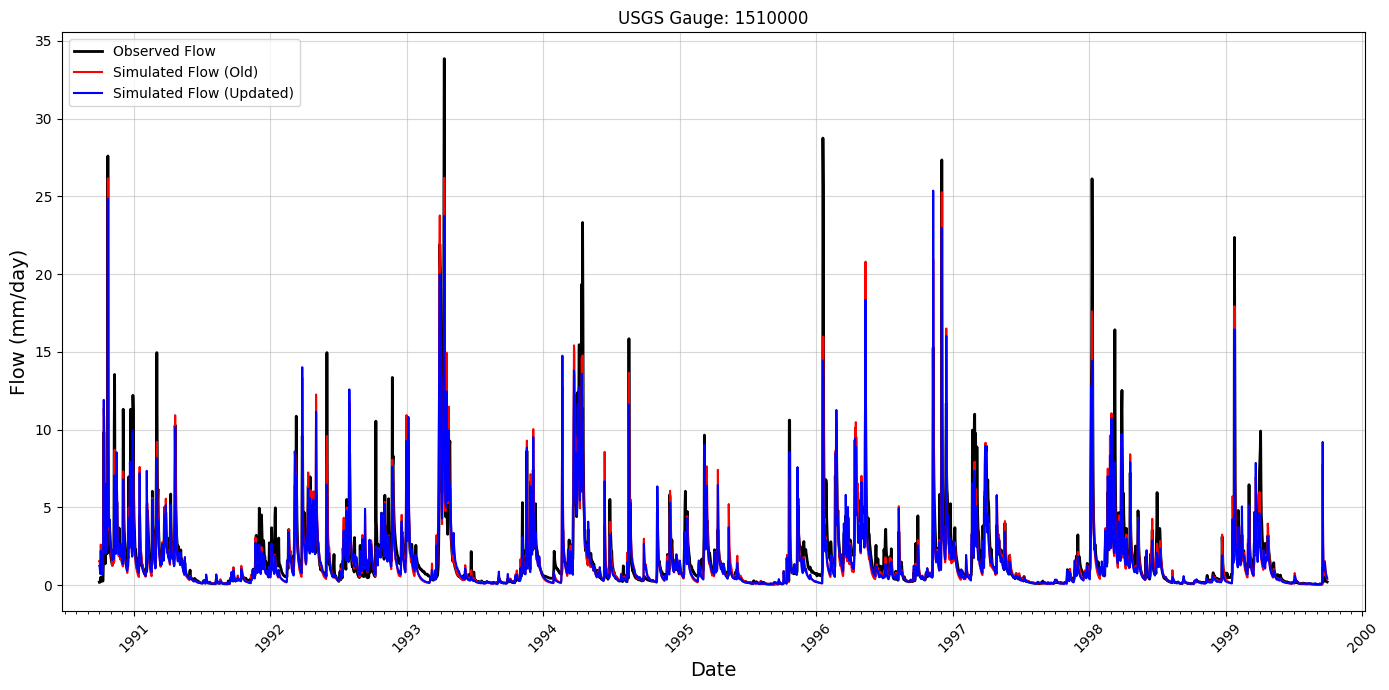

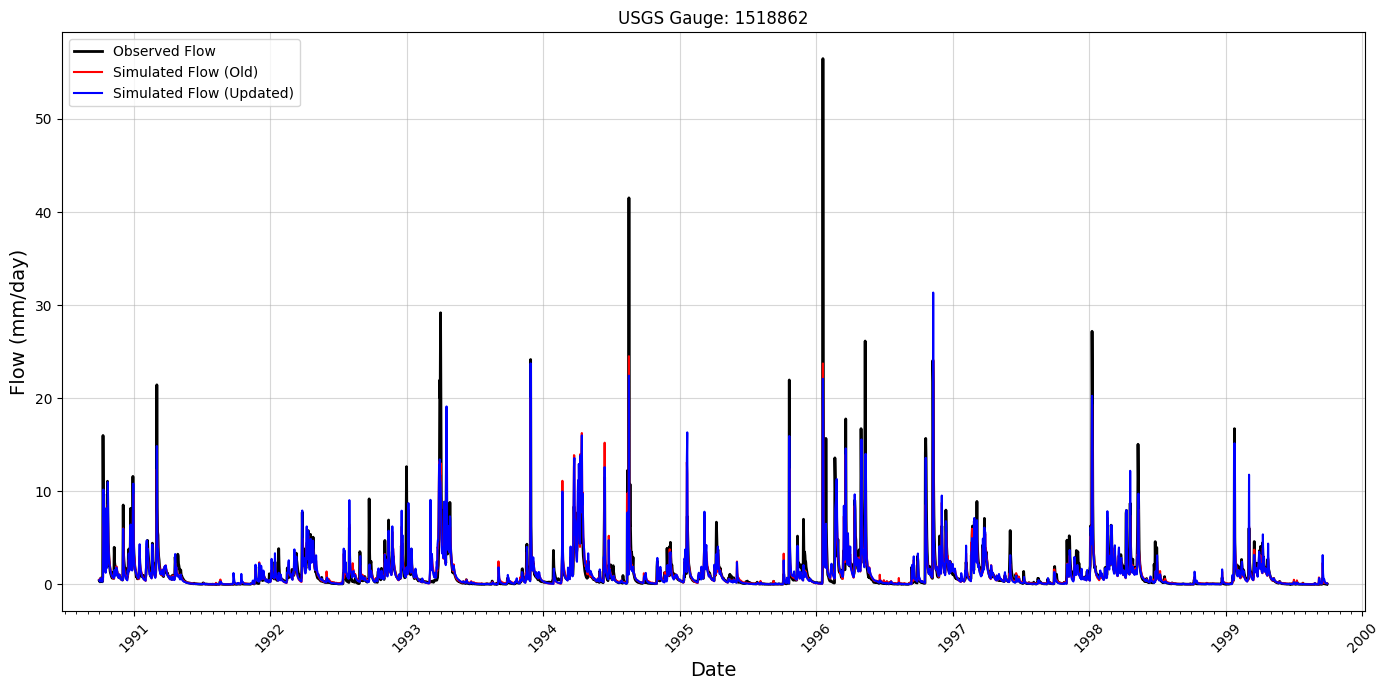

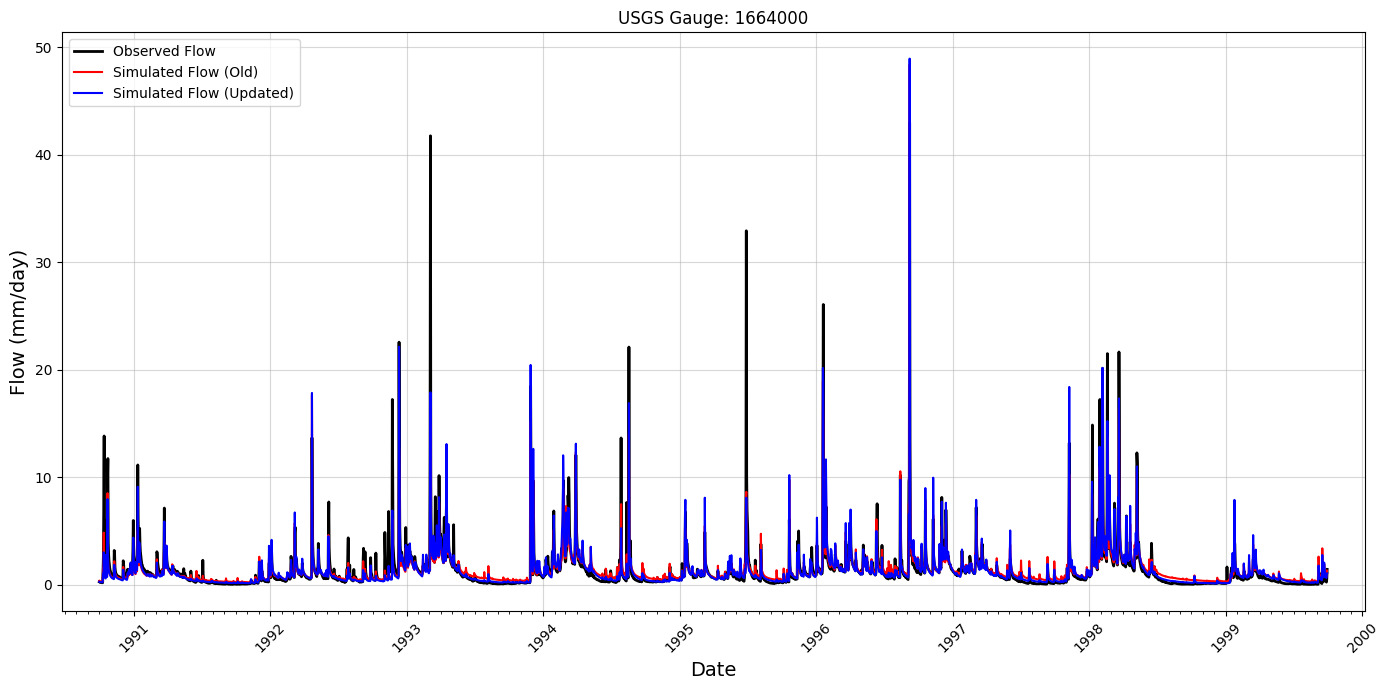

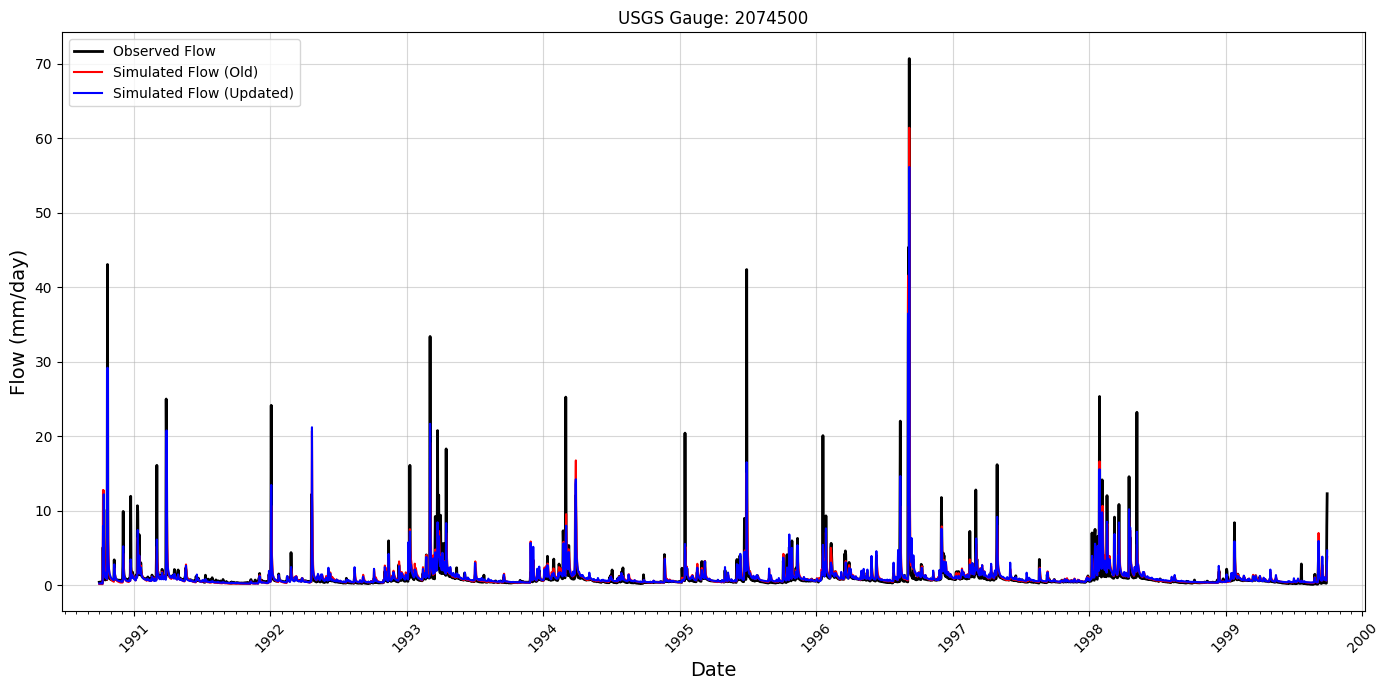

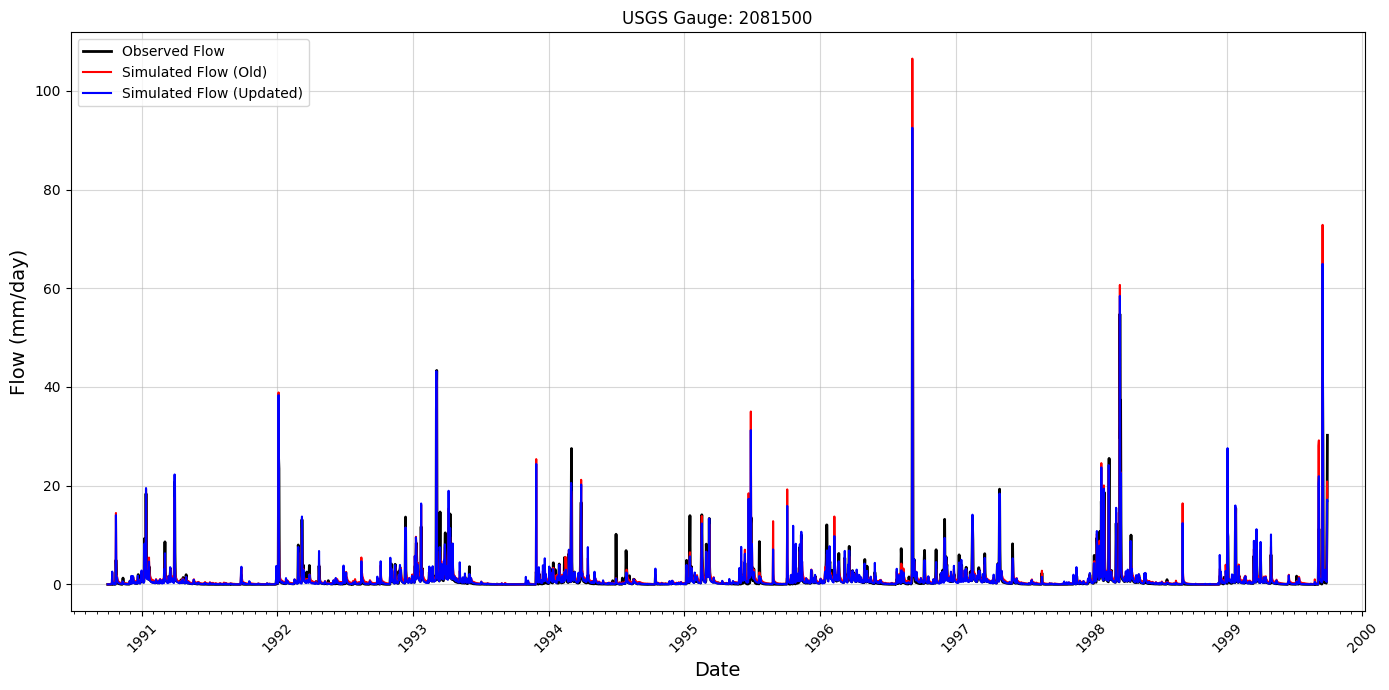

In [90]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.dates as mdates
from pandas import Timedelta

# ----------------------------------------
# Load gauge IDs
# ----------------------------------------
gauge = np.load(
    "/home/s0shar47/scratch/BASEFLOW_FOLDS/10/test/DAYMET_19800101_20141231_forcing_baseflow_mmday.npy"
)

# ----------------------------------------
# Create date axis
# (Warm-up period removed, so data start at 1990-10-01)
# ----------------------------------------
dates = pd.date_range(
    start="1990-10-01",
    periods=ob_flow.shape[0],
    freq="D"
)

# ----------------------------------------
# Plot first 10 basins
# ----------------------------------------
for i in range(10):

    fig, ax = plt.subplots(figsize=(14, 7))

    gid = int(gauge[i, 0, -2])

    # Plot using dates as x-axis
    ax.plot(
        dates,
        ob_flow[:, i],
        color="black",
        linewidth=2,
        label="Observed Flow"
    )

    ax.plot(
        dates,
        sim_flow_old[:, i],
        color="red",
        linewidth=1.5,
        label="Simulated Flow (Old)"
    )

    ax.plot(
        dates,
        sim_flow_new[:, i],
        color="blue",
        linewidth=1.5,
        label="Simulated Flow (Updated)"
    )

    # Add 100-day padding on both sides
    buffer = Timedelta(days=100)
    ax.set_xlim(dates[0] - buffer, dates[-1] + buffer)

    # Major ticks every year
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    # Minor ticks every month (optional)
    ax.xaxis.set_minor_locator(mdates.MonthLocator())

    plt.xticks(rotation=45)

    ax.set_xlabel("Date", fontsize=14)
    ax.set_ylabel("Flow (mm/day)", fontsize=14)
    ax.set_title(f"USGS Gauge: {gid}")

    ax.grid(True, which="major", alpha=0.5)
    ax.legend(loc="upper left")

    plt.tight_layout()
    plt.show()

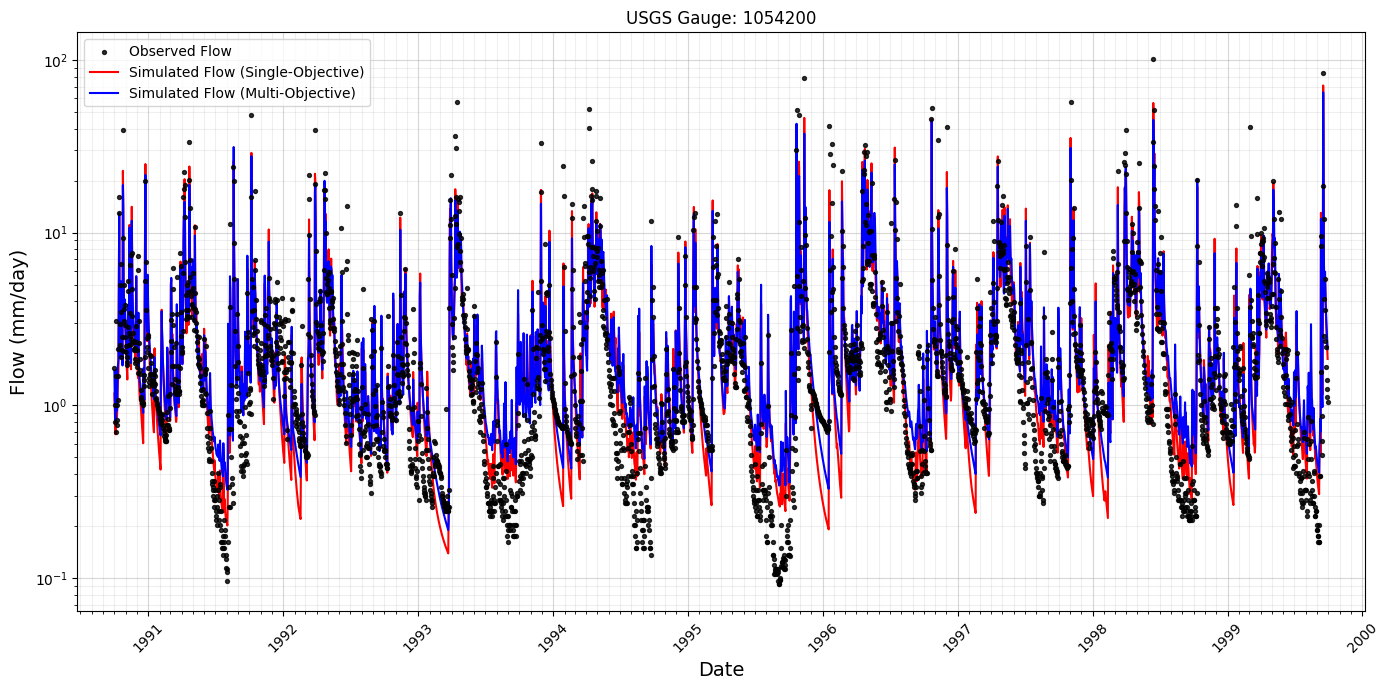

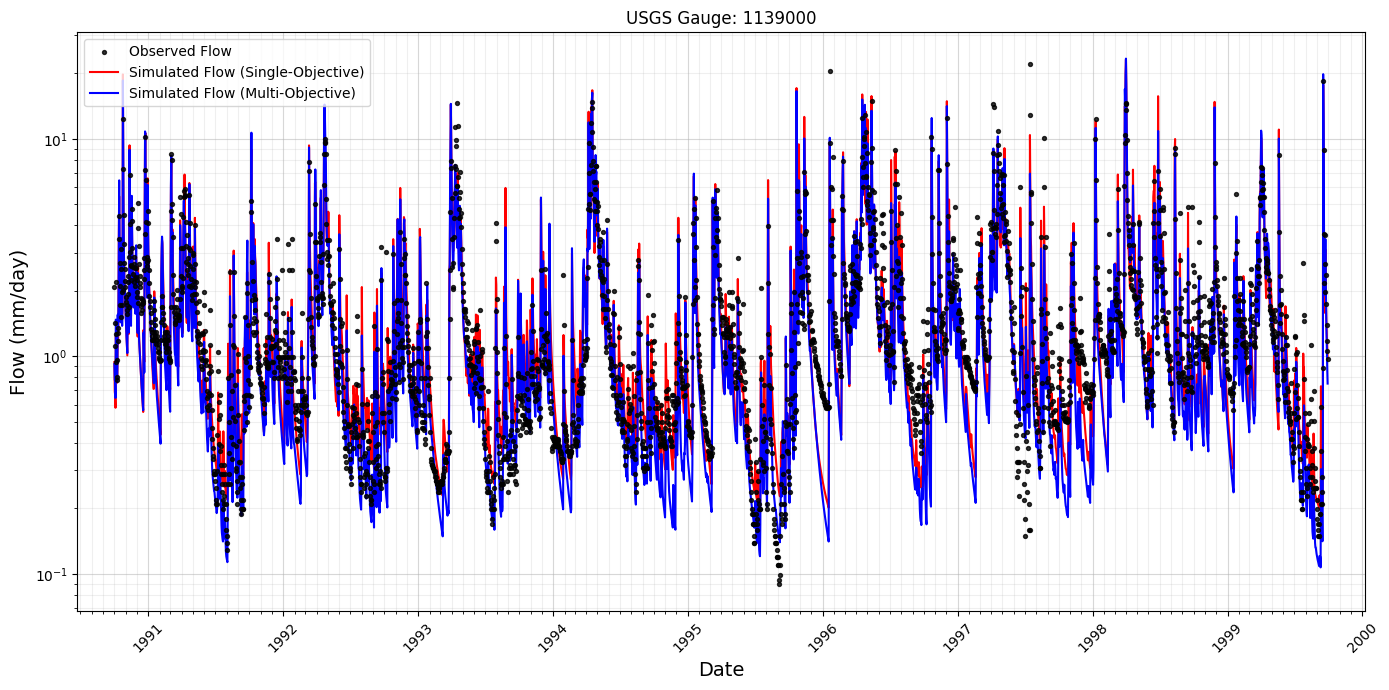

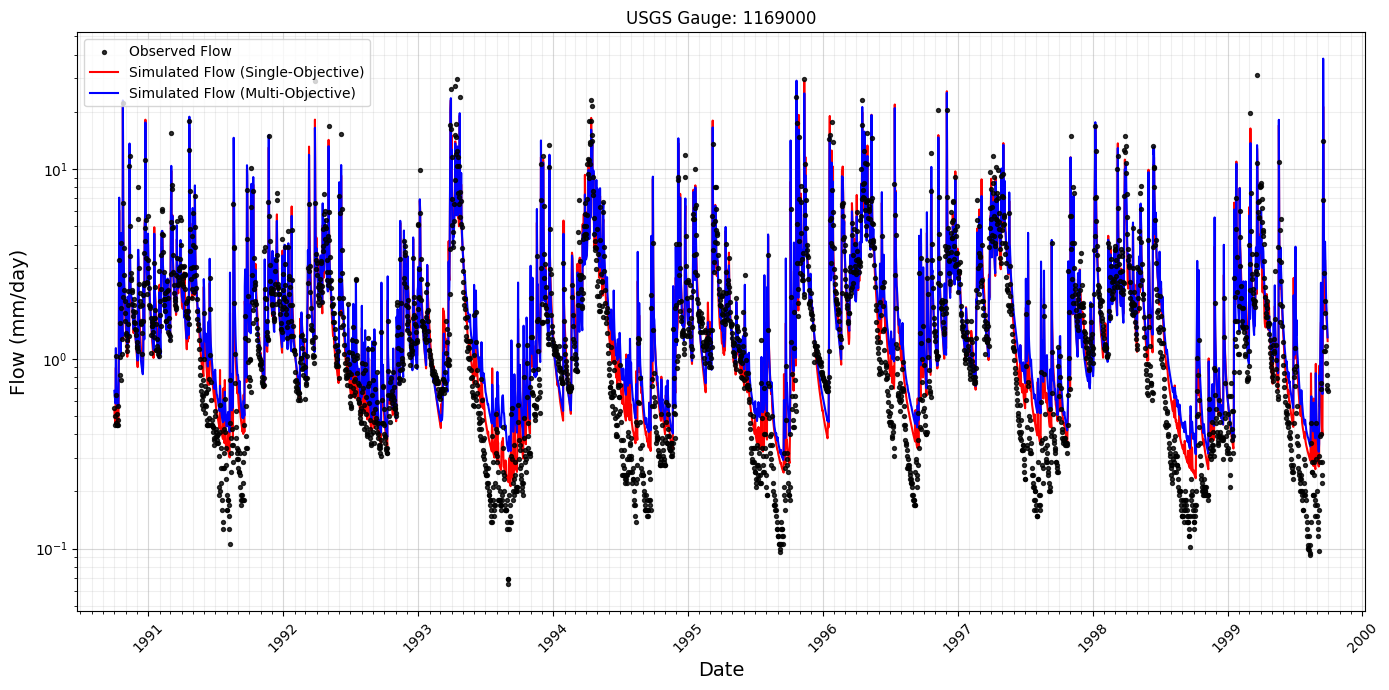

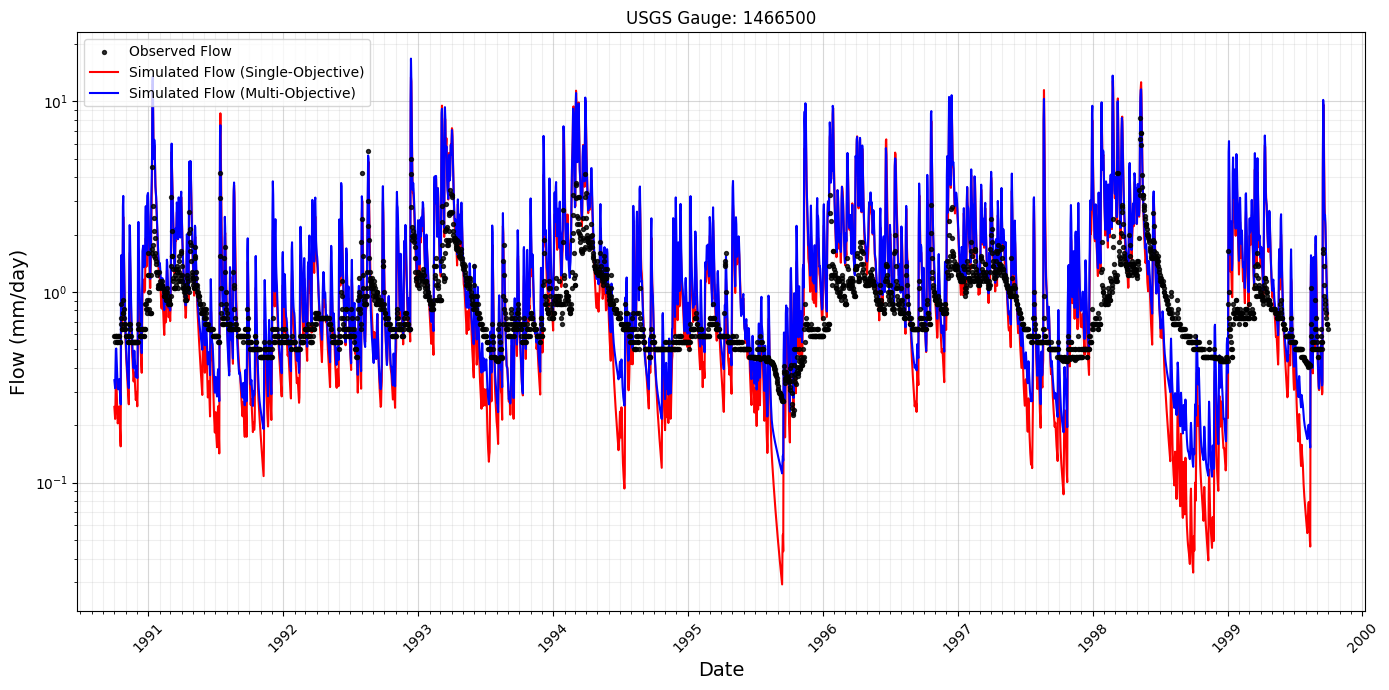

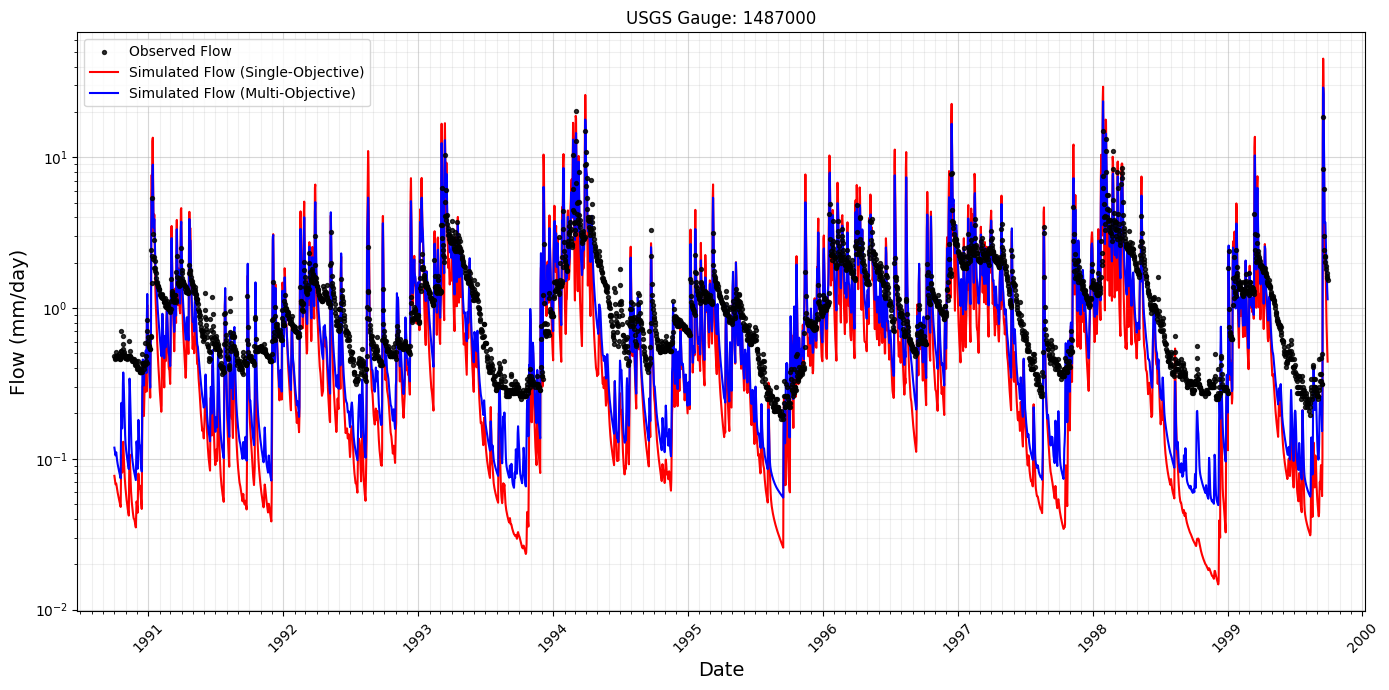

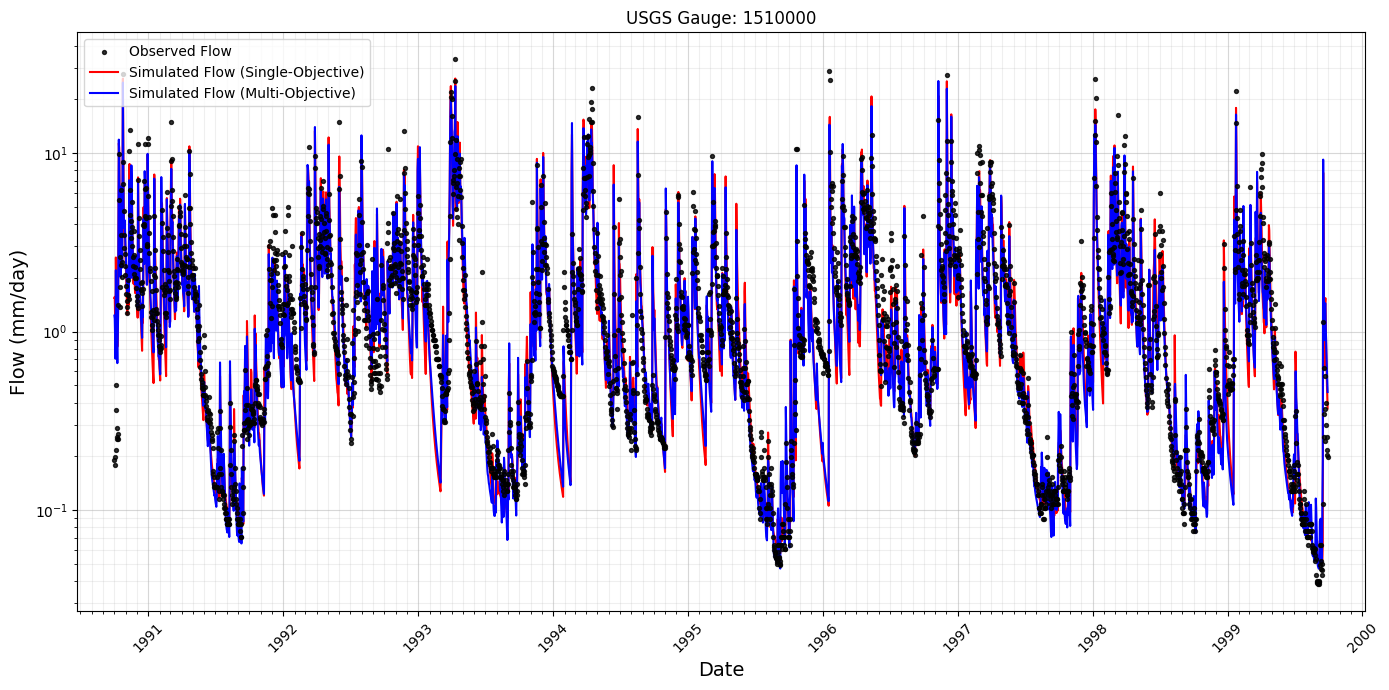

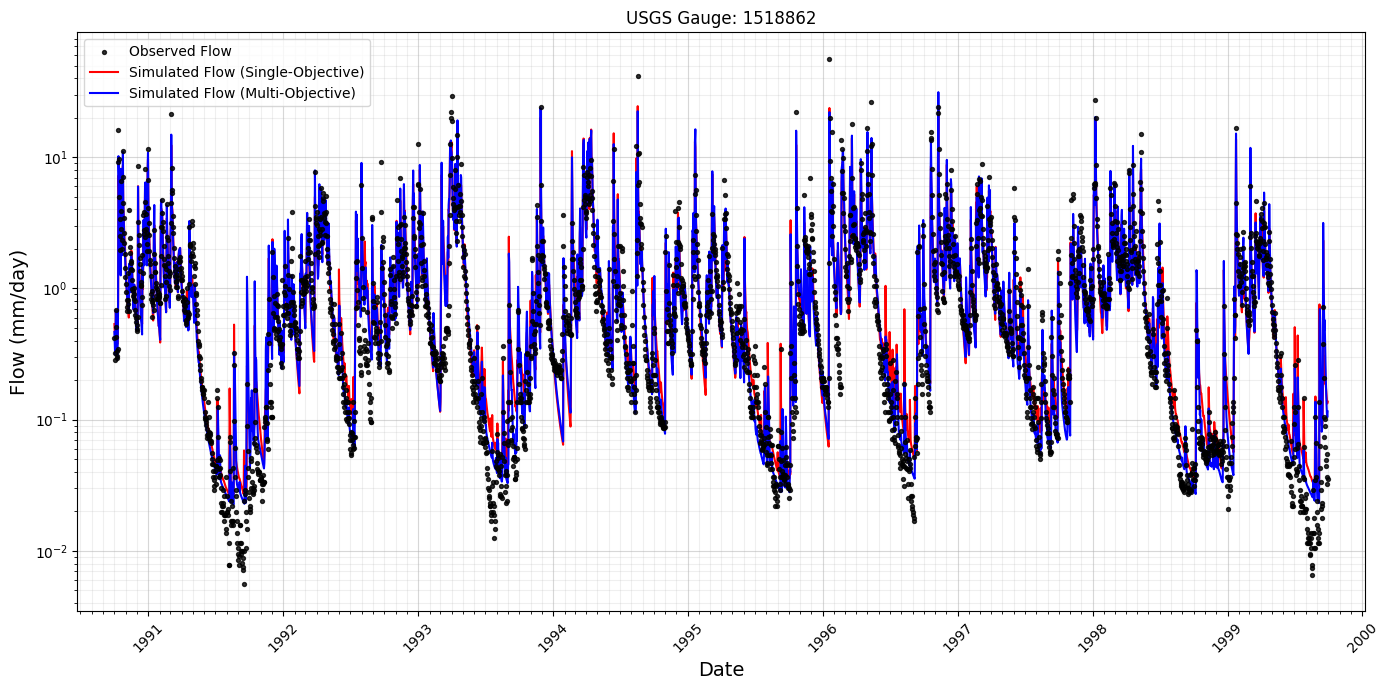

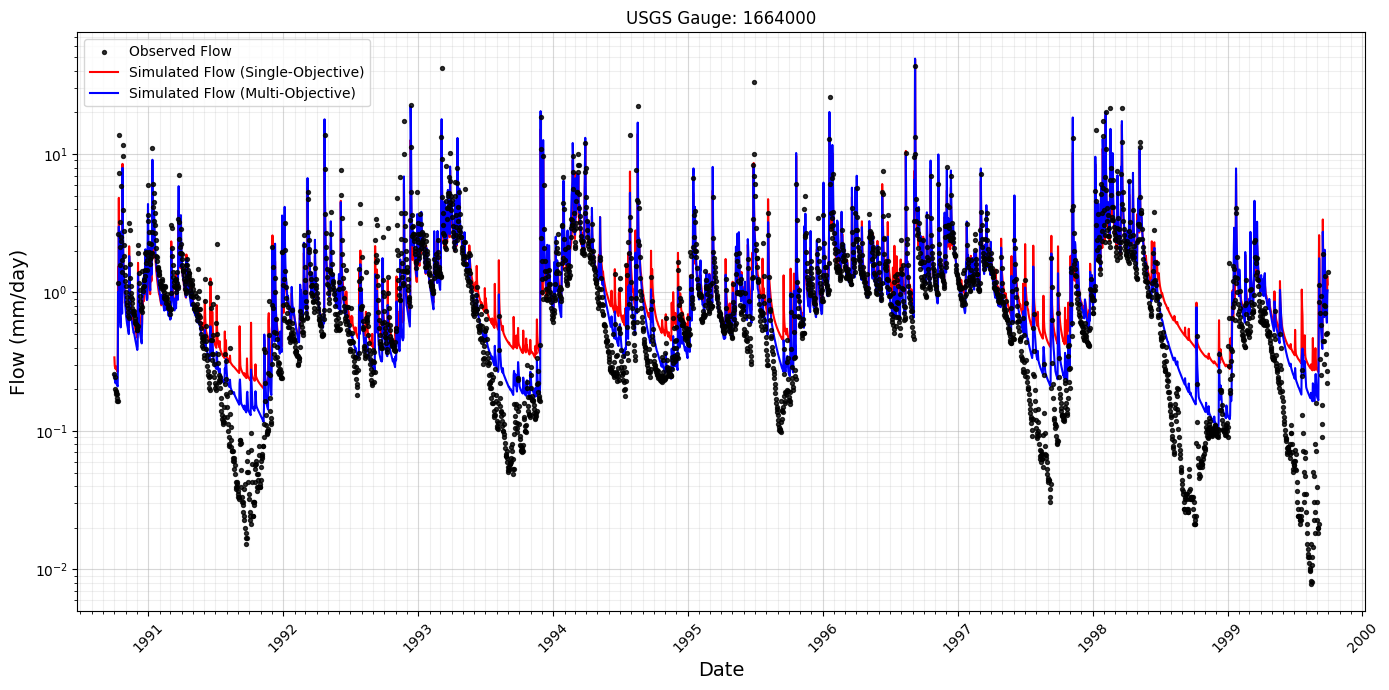

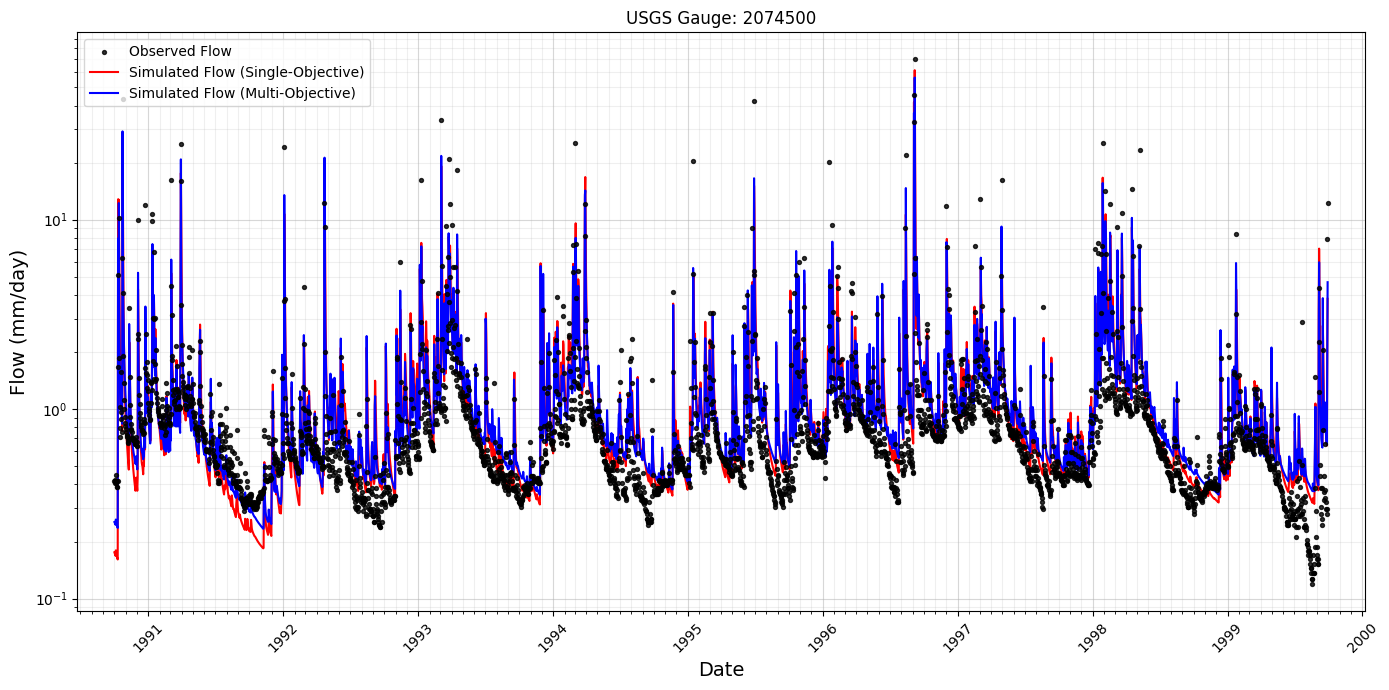

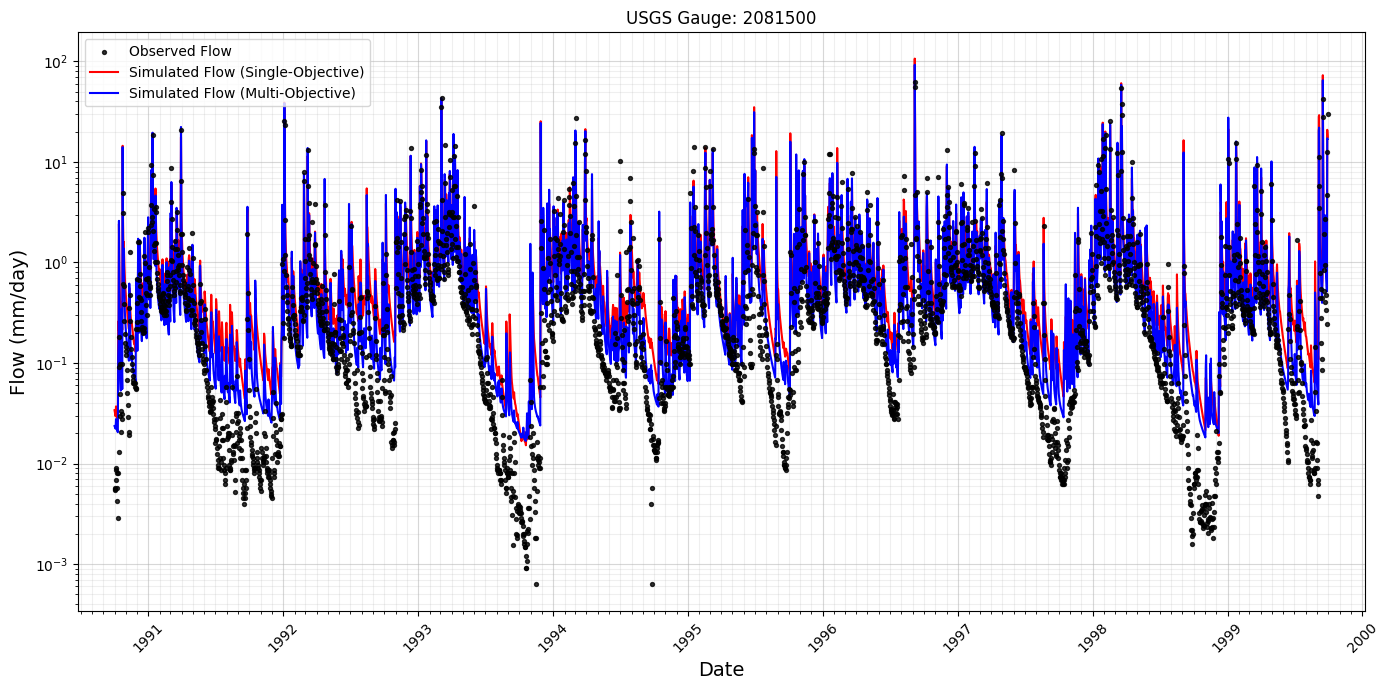

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.dates as mdates
from pandas import Timedelta

# ----------------------------------------
# Load gauge IDs
# ----------------------------------------
gauge = np.load(
    "/home/s0shar47/scratch/BASEFLOW_FOLDS/10/test/DAYMET_19800101_20141231_forcing_baseflow_mmday.npy"
)

# ----------------------------------------
# Date axis
# ----------------------------------------
dates = pd.date_range(
    start="1990-10-01",
    periods=ob_flow.shape[0],
    freq="D"
)

# ----------------------------------------
# Plot first 10 basins
# ----------------------------------------
for i in range(10):


    fig, ax = plt.subplots(figsize=(14, 7))

    gid = int(gauge[i, 0, -2])

    obs = ob_flow[:, i].copy()
    sim_old = sim_flow_old[:, i].copy()
    sim_new = sim_flow_new[:, i].copy()

    # Replace non-positive values with NaN for log scale
    obs[obs <= 0] = np.nan
    sim_old[sim_old <= 0] = np.nan
    sim_new[sim_new <= 0] = np.nan

    # Observations as scatter
    ax.scatter(
        dates,
        obs,
        color="black",
        s=8,
        alpha=0.8,
        label="Observed Flow",
        zorder=3,
    )

    # Simulations as lines
    ax.plot(
        dates,
        sim_old,
        color="red",
        linewidth=1.5,
        label="Simulated Flow (Single-Objective)",
        zorder=2,
    )

    ax.plot(
        dates,
        sim_new,
        color="blue",
        linewidth=1.5,
        label="Simulated Flow (Multi-Objective)",
        zorder=2,
    )

    # Logarithmic y-axis
    ax.set_yscale("log")

    # Add padding
    buffer = Timedelta(days=100)
    ax.set_xlim(dates[0] - buffer, dates[-1] + buffer)

    # Year ticks
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.xaxis.set_minor_locator(mdates.MonthLocator())

    plt.xticks(rotation=45)

    ax.set_xlabel("Date", fontsize=14)
    ax.set_ylabel("Flow (mm/day)", fontsize=14)
    ax.set_title(f"USGS Gauge: {gid}")

    ax.grid(True, which="major", alpha=0.5)
    ax.grid(True, which="minor", alpha=0.2)

    ax.legend(loc="upper left")

    plt.tight_layout()
    plt.show()




(3286,)

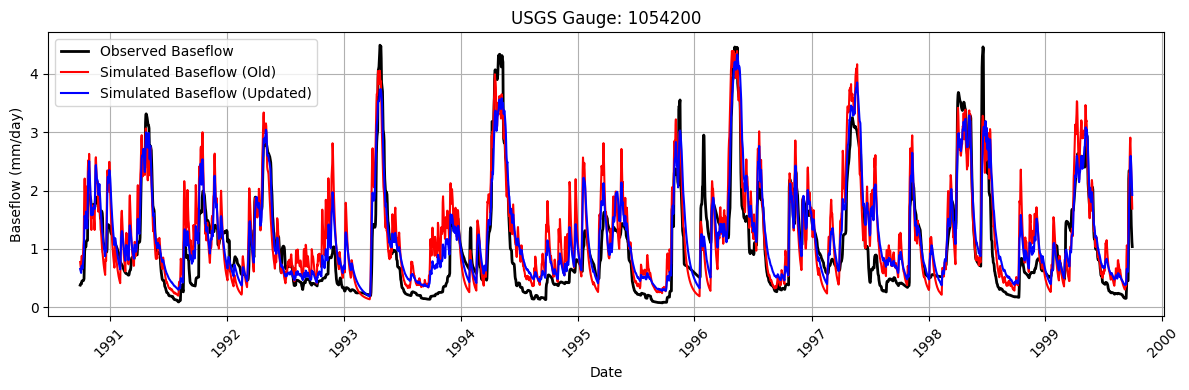

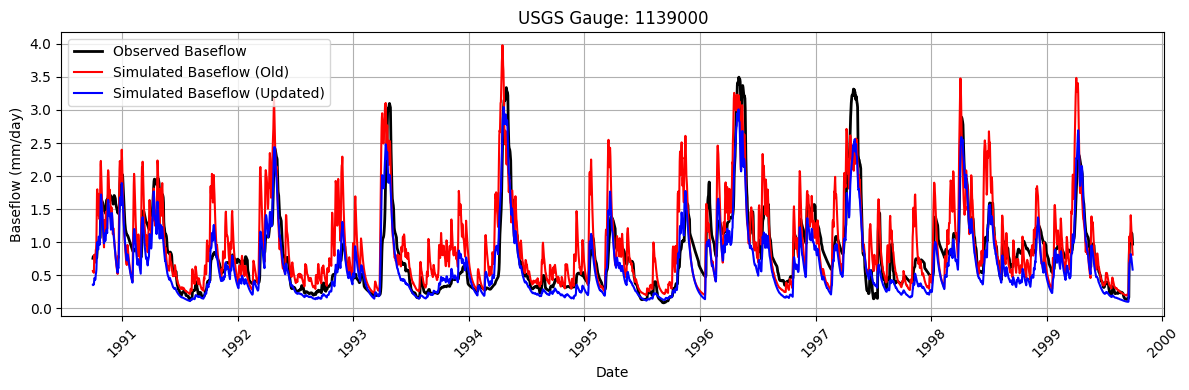

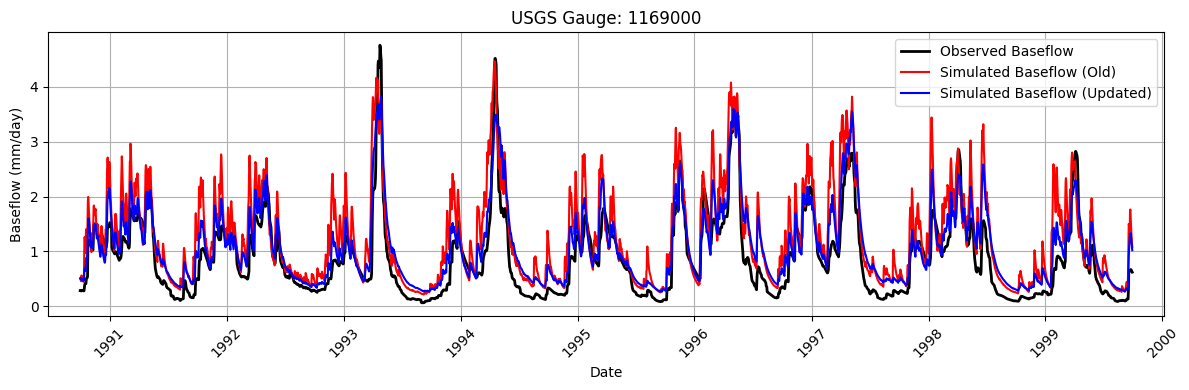

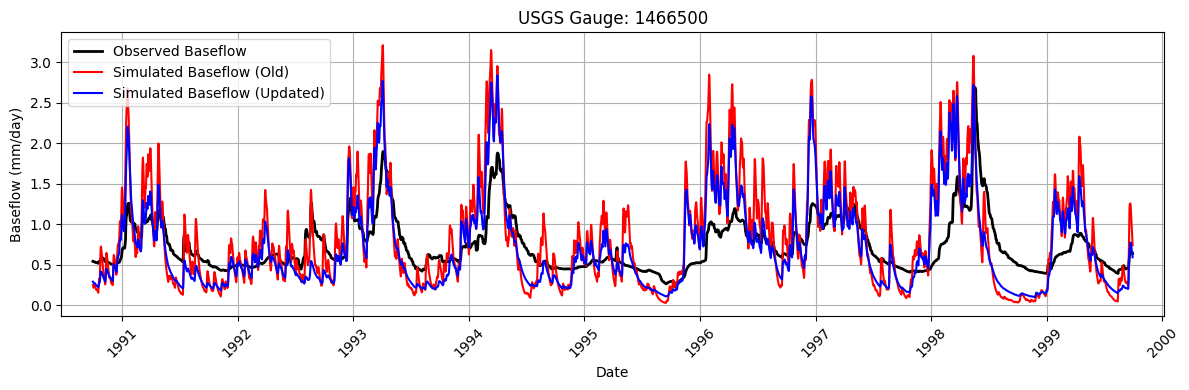

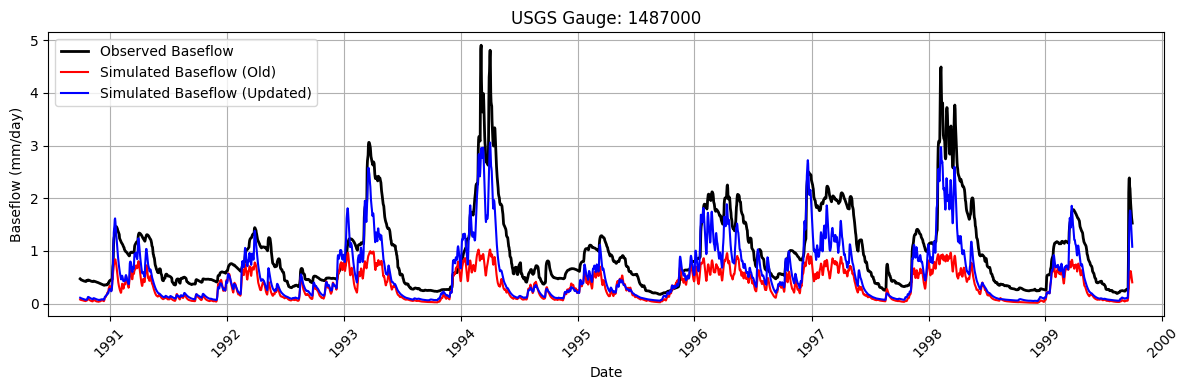

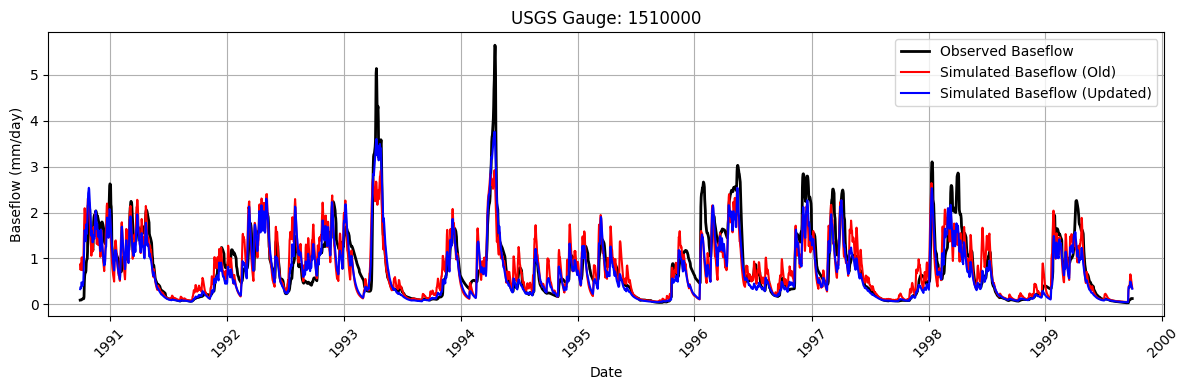

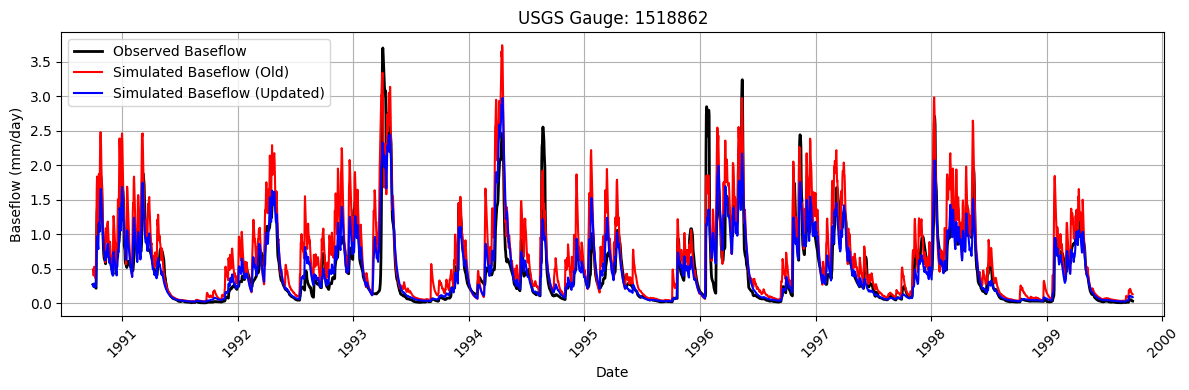

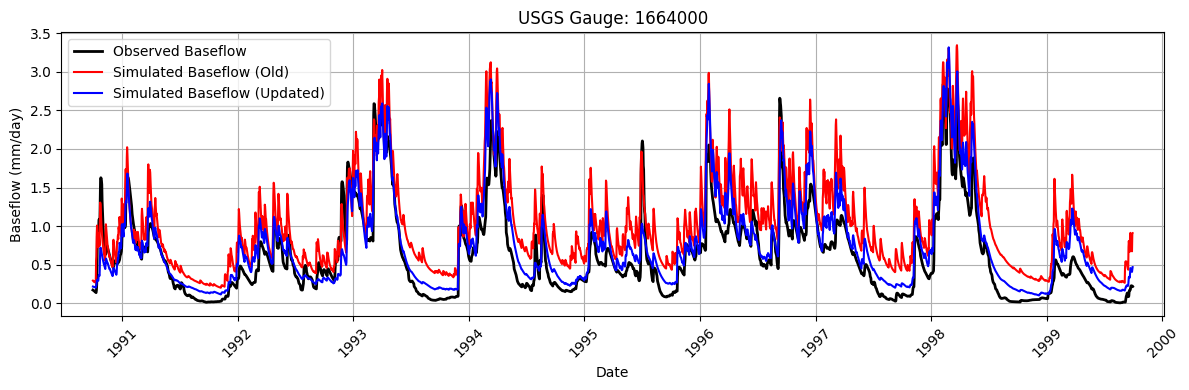

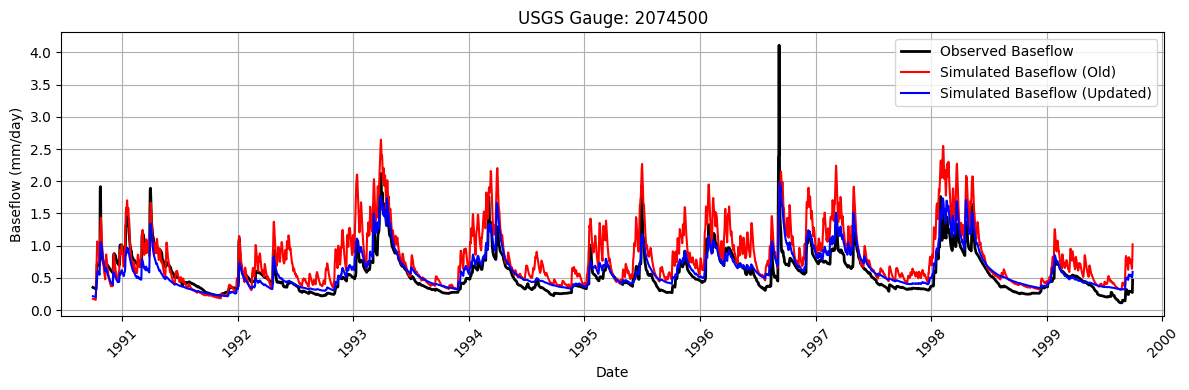

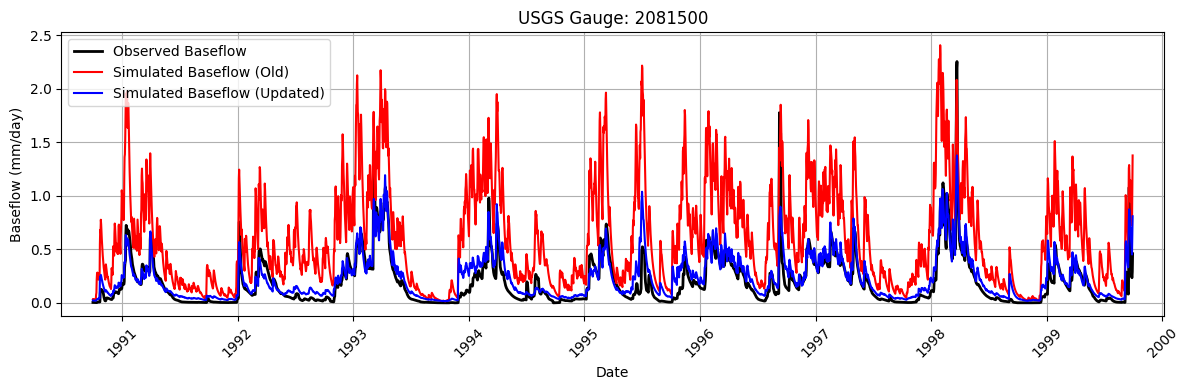

In [67]:
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.dates as mdates
from pandas import Timedelta


gauge= np.load(f"/home/s0shar47/scratch/BASEFLOW_FOLDS/10/test/DAYMET_19800101_20141231_forcing_baseflow_mmday.npy")
dates = pd.date_range(
    start="1990-10-01",
    periods=ob_flow.shape[0],
    freq="D"
)

for i in range(10):

    gid = int(gauge[i, 0, -2])
    
    plt.figure(figsize=(12, 4))


    plt.plot(dates, ob_baseflow[:, i], label="Observed Baseflow", color="black", linewidth=2)
    plt.plot(dates, sim_gwflow_old[:, i], label="Simulated Baseflow (Old)", color="red")
    plt.plot(dates, sim_gwflow_new[:, i], label="Simulated Baseflow (Updated)", color="blue")

    ax = plt.gca()
    buffer = Timedelta(days=100)
    ax.set_xlim(dates[0] - buffer, dates[-1] + buffer)
    # ax.set_xlim(dates[0], dates[-1])
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    plt.xlabel("Date")
    plt.ylabel("Baseflow (mm/day)")
    plt.title(f"USGS Gauge: {gid}")
    plt.grid(True)
    plt.legend()

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


In [ ]:
import numpy as np
import pandas as pd

ob_bfis = []
sim1_bfis = []
sim2_bfis = []

gids = []
nses1 = []
nses2 = []

nses3= []
nses4= []

for i in range(1, 11):

    gauge = np.load(
        f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/test/DAYMET_19800101_20141231_forcing_baseflow_mmday.npy"
    )

    ob_flow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/00060_Mean.npy"
    )

    ob_baseflow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/baseflow.npy"
    )

    sim_flow_old = np.squeeze(np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
    ))

    sim_flow_new = np.squeeze(np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
    ))

    sim_gwflow_old = np.squeeze(np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/gwflow.npy"
    ))

    sim_gwflow_new = np.squeeze(np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/gwflow.npy"
    ))

    for k in range(ob_baseflow.shape[1]):

        gid = int(gauge[k, 0, -2])

        obs = ob_baseflow[:, k]
        old = sim_gwflow_old[:, k]
        new = sim_gwflow_new[:, k]

        # NSE
        den = np.sum((obs - obs.mean()) ** 2)

        if den > 0:
            nse1 = 1 - np.sum((obs - old) ** 2) / den
            nse2 = 1 - np.sum((obs - new) ** 2) / den
        else:
            nse1 = np.nan
            nse2 = np.nan

        # BFI
        obs_flow_sum = np.sum(ob_flow[:, k])
        old_flow_sum = np.sum(sim_flow_old[:, k])
        new_flow_sum = np.sum(sim_flow_new[:, k])

        obs_bfi = np.sum(obs) / obs_flow_sum if obs_flow_sum > 0 else np.nan
        old_bfi = np.sum(old) / old_flow_sum if old_flow_sum > 0 else np.nan
        new_bfi = np.sum(new) / new_flow_sum if new_flow_sum > 0 else np.nan

##Flow
        obs = ob_flow[:, k]
        old = sim_flow_old[:, k]
        new = sim_flow_new[:, k]

        # NSE
        den = np.sum((obs - obs.mean()) ** 2)

        if den > 0:
            nse3 = 1 - np.sum((obs - old) ** 2) / den
            nse4 = 1 - np.sum((obs - new) ** 2) / den
        else:
            nse3 = np.nan
            nse4 = np.nan

        

        gids.append(gid)
        nses1.append(nse1)
        nses2.append(nse2)
        nses3.append(nse3)
        nses4.append(nse4)

        ob_bfis.append(obs_bfi)
        sim1_bfis.append(old_bfi)
        sim2_bfis.append(new_bfi)

df = pd.DataFrame({
    "GaugeID": gids,
    "Observed BFI": ob_bfis,
    "Simulated BFI (Single)": sim1_bfis,
    "Simulated BFI (Multi)": sim2_bfis,
    "NSE Baseflow(Single)": nses1,
    "NSE Baseflow(Multi)": nses2,
    "NSE Flow(Single)": nses3,
    "NSE Flow(Multi)": nses4,
})
df
df.to_csv("BFIand Baseflow_metrics.csv", index= False)

In [130]:
ob_baseflow.shape

(3286, 56)

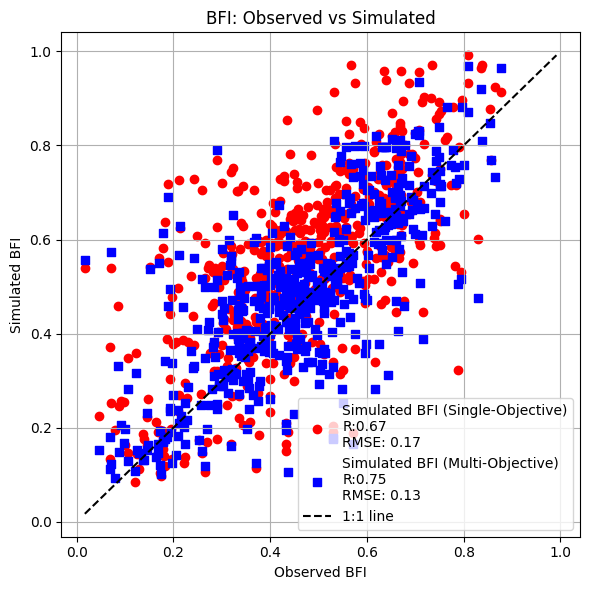

In [136]:
import matplotlib.pyplot as plt
import numpy as np

# Extract arrays
x = df['Observed BFI'].values
y1 = df['Simulated BFI (Single)'].values
y2 = df['Simulated BFI (Multi)'].values

corr1= df['Observed BFI'].corr(df['Simulated BFI (Single)'])
rmse1= np.sqrt(((df['Observed BFI']-df['Simulated BFI (Single)'])**2).mean())
corr2= df['Observed BFI'].corr(df['Simulated BFI (Multi)'])
rmse2= np.sqrt(((df['Observed BFI']-df['Simulated BFI (Multi)'])**2).mean())

plt.figure(figsize=(6,6))

# Scatter plots
plt.scatter(x, y1, marker='o', label= f'Simulated BFI (Single-Objective)\nR:{corr1:.2f}\nRMSE: {rmse1:.2f}', color='red')
plt.scatter(x, y2, marker='s', label= f'Simulated BFI (Multi-Objective)\nR:{corr2:.2f}\nRMSE: {rmse2:.2f}', color='blue')

# 1:1 line
min_val = min(np.min(x), np.min(y1), np.min(y2))
max_val = max(np.max(x), np.max(y1), np.max(y2))
plt.plot([min_val, max_val], [min_val, max_val], 'k--', label='1:1 line')

# Labels and styling
plt.xlabel('Observed BFI')
plt.ylabel('Simulated BFI')
plt.title('BFI: Observed vs Simulated')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [63]:
import numpy as np

# =========================================================
# 1. METRIC FUNCTIONS
# =========================================================

def nse(obs, sim):
    den = np.sum((obs - np.mean(obs)) ** 2)
    return 1 - np.sum((obs - sim) ** 2) / den


def bias(obs, sim):
    return np.sum(sim - obs) / np.sum(obs)


def kge(obs, sim):
    r = np.corrcoef(obs, sim)[0, 1]
    alpha = np.std(sim) / np.std(obs)
    beta = np.mean(sim) / np.mean(obs)

    return 1 - np.sqrt((r - 1) ** 2 + (alpha - 1) ** 2 + (beta - 1) ** 2)


def split_flows(obs, low_q=0.2, high_q=0.8):
    ql = np.quantile(obs, low_q)
    qh = np.quantile(obs, high_q)

    low = obs <= ql
    high = obs >= qh
    return low, high


def compute_metrics(obs, sim):
    obs = np.asarray(obs)
    sim = np.asarray(sim)

    low_idx, high_idx = split_flows(obs)

    return {
        "NSE": nse(obs, sim),
        "KGE": kge(obs, sim),
        "Bias": bias(obs, sim),

        "NSE_low": nse(obs[low_idx], sim[low_idx]),
        "NSE_high": nse(obs[high_idx], sim[high_idx]),

        "Bias_low": bias(obs[low_idx], sim[low_idx]),
        "Bias_high": bias(obs[high_idx], sim[high_idx]),
    }


# =========================================================
# 2. STORAGE
# =========================================================

all_ob_flow = []
all_ob_baseflow = []

all_sim_flow_old = []
all_sim_flow_new = []

all_sim_gw_old = []
all_sim_gw_new = []


# =========================================================
# 3. LOAD + FLATTEN (10 FOLDS)
# =========================================================

for i in range(1, 11):

    ob_flow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/"
        f"LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/"
        f"parBETA_parBETAET_/ts1989_1999/00060_Mean.npy"
    )

    ob_baseflow = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/"
        f"LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/"
        f"parBETA_parBETAET_/ts1989_1999/baseflow.npy"
    )

    sim_flow_old = np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS/{i}/"
        f"LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/"
        f"parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
    )

    sim_flow_new = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/"
        f"LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/"
        f"parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
    )

    sim_gw_old = np.load(
        f"/home/s0shar47/scratch/DAYMET_FOLDS_OUTPUTS/{i}/"
        f"LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/"
        f"parBETA_parBETAET_/ts1989_1999/gwflow.npy"
    )

    sim_gw_new = np.load(
        f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/"
        f"LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/"
        f"parBETA_parBETAET_/ts1989_1999/gwflow.npy"
    )

    # squeeze + flatten
    sim_flow_old = np.squeeze(sim_flow_old).ravel()
    sim_flow_new = np.squeeze(sim_flow_new).ravel()
    sim_gw_old = np.squeeze(sim_gw_old).ravel()
    sim_gw_new = np.squeeze(sim_gw_new).ravel()

    all_ob_flow.append(ob_flow.ravel())
    all_ob_baseflow.append(ob_baseflow.ravel())

    all_sim_flow_old.append(sim_flow_old)
    all_sim_flow_new.append(sim_flow_new)

    all_sim_gw_old.append(sim_gw_old)
    all_sim_gw_new.append(sim_gw_new)


# =========================================================
# 4. CONCATENATE ACROSS FOLDS
# =========================================================

flat_ob_flow = np.concatenate(all_ob_flow)
flat_ob_baseflow = np.concatenate(all_ob_baseflow)

flat_sim_flow_old = np.concatenate(all_sim_flow_old)
flat_sim_flow_new = np.concatenate(all_sim_flow_new)

flat_sim_gw_old = np.concatenate(all_sim_gw_old)
flat_sim_gw_new = np.concatenate(all_sim_gw_new)


# =========================================================
# 5. GLOBAL METRICS
# =========================================================

flow_old_metrics = compute_metrics(flat_ob_flow, flat_sim_flow_old)
flow_new_metrics = compute_metrics(flat_ob_flow, flat_sim_flow_new)

base_old_metrics = compute_metrics(flat_ob_baseflow, flat_sim_gw_old)
base_new_metrics = compute_metrics(flat_ob_baseflow, flat_sim_gw_new)


# =========================================================
# 6. PRINT COMPARISON
# =========================================================

def print_comparison(name, m_old, m_new):
    print("\n" + "=" * 60)
    print(f"{name} COMPARISON")
    print("=" * 60)

    for k in m_old.keys():
        print(f"{k:12s}: {m_old[k]:.4f} → {m_new[k]:.4f}")


print_comparison("FLOW", flow_old_metrics, flow_new_metrics)
print_comparison("BASEFLOW", base_old_metrics, base_new_metrics)


FLOW COMPARISON
NSE         : 0.7753 → 0.7655
KGE         : 0.8195 → 0.7931
Bias        : -0.0223 → -0.0490
NSE_low     : -38.8250 → -33.0060
NSE_high    : 0.6779 → 0.6626
Bias_low    : 2.1725 → 1.8368
Bias_high   : -0.0963 → -0.1178

BASEFLOW COMPARISON
NSE         : 0.7053 → 0.7775
KGE         : 0.7556 → 0.8443
Bias        : 0.0965 → 0.0032
NSE_low     : -51.6637 → -25.2809
NSE_high    : 0.4319 → 0.5329
Bias_low    : 3.5154 → 2.2999
Bias_high   : -0.0802 → -0.0723
